<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ Big Data Competition Statistics Explore 2026 ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Klasifikasi jenis bencana dan tingkat kerusakan dari citra</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

*Membangun ulang kepala tingkat kerusakan pada proses DINOv3 di sekitar multiple-instance pooling, derau label yang terukur, dan aturan keputusan ordinal.*

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **Nama Tim**

<p style="font-size:16px; font-family:verdana">- Riantama Putra <br>- Farrel Athalla Putra<br>- Ayu Nagita Cahyaning Wulan</p>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Rancangan Validasi**](#4)
5. [**Preprocessing**](#5)
6. [**Modelling**](#6)
7. [**Training**](#7)
8. [**Evaluation**](#8)
9. [**Inferensi dan Submisi**](#9)
10. [**Kesimpulan**](#10)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Bencana alam meninggalkan dua pertanyaan yang harus dijawab cepat oleh tim tanggap darurat: *bencana apa yang terjadi* dan *seberapa parah kerusakannya*. Menjawab keduanya secara manual dari ribuan foto lapangan memakan waktu yang justru paling langka pada jam-jam pertama pascabencana.

Pada **Big Data Competition Statistics Explore 2026** jalur citra, peserta diminta memberi dua label untuk setiap foto bencana alam: **jenis bencana** (`jenis`) di antara banjir, gempa bumi dan kebakaran, serta **tingkat kerusakan** (`kerusakan`) di antara ringan, sedang dan berat.

- **Tugas**: klasifikasi citra dengan dua target sekaligus
- **Kelas `jenis`**: `BANJIR`, `GEMPA BUMI`, `KEBAKARAN`
- **Kelas `kerusakan`**: `KERUSAKAN RINGAN`, `KERUSAKAN SEDANG`, `KERUSAKAN BERAT`

---

## Tujuan

Melakukan *fine-tuning* **DINOv3 ViT-7B/16 dengan kepala khusus tingkat kerusakan** menjadi pengklasifikasi berkepala ganda yang memprediksi `jenis` dan `kerusakan` secara bersamaan.

---

## Metrik

***Micro F1-Score** menjumlahkan *true positive*, *false positive* dan *false negative* atas seluruh kelas terlebih dahulu, baru menghitung rasionya, alih-alih merata-ratakan skor per kelas.*

$$\text{F1}_{\text{micro}} = \frac{2 \cdot \text{TP}}{2 \cdot \text{TP} + \text{FP} + \text{FN}}$$

Submisi berisi tepat 900 baris: 450 citra dikali dua target. Setiap baris membawa tepat satu label prediksi dan tepat satu label sebenarnya, sehingga setiap baris menyumbang satu *true positive*, atau satu *false positive* ditambah satu *false negative*. Substitusi keadaan itu ke persamaan di atas meruntuhkannya menjadi akurasi biasa atas 900 baris:

$$\text{F1}_{\text{micro}} = \frac{\text{baris benar}}{900} = \tfrac{1}{2}\left(\text{akurasi}_{\text{jenis}} + \text{akurasi}_{\text{kerusakan}}\right)$$

Konsekuensi praktisnya, kedua tugas berbobot sama. Menaikkan kepala `kerusakan` yang lebih sulit sebesar satu poin bernilai persis sama dengan menaikkan kepala `jenis` yang lebih mudah sebesar satu poin. Karena itu *notebook* melaporkan keduanya secara terpisah, agar usaha dapat diarahkan ke sisi yang tertinggal.

---

## Dataset

*Data bersumber dari Kaggle: https://www.kaggle.com/competitions/big-data-competition-statistics-explore-2026*

*Dataset* memuat 17.482 citra latih berlabel yang tersebar pada sembilan folder jenis-kali-kerusakan, serta 450 citra uji tanpa label. Cacah kelas berkisar dari 1.393 hingga 2.730 per sel, rentang 1,96 kali yang masih cukup landai sehingga tidak memerlukan penyeimbangan ulang.

Hasil *scraping* ini heterogen: muncul 3.909 resolusi berbeda, empat format wadah dan empat mode warna, sehingga jalur pemuatan harus menormalkan secara agresif sebelum satu tensor pun dihasilkan.

```
SE/
|-- TRAIN/
|    |-- BANJIR/
|    |    |-- KERUSAKAN RINGAN/
|    |    |-- KERUSAKAN SEDANG/
|    |    +-- KERUSAKAN BERAT/
|    |-- GEMPA BUMI/
|    |    +-- (tiga folder kerusakan yang sama)
|    |-- KEBAKARAN/
|    |    +-- (tiga folder kerusakan yang sama)
|    +-- Solution.csv          <- templat submisi, 900 baris
+-- TEST/
     +-- 1.jpg ... 450.jpg
```

**Format submisi**

```
ID,Target
1_jenis,<jenis bencana>
1_kerusakan,<tingkat kerusakan>
2_jenis,<jenis bencana>
...
```

Notebook ini melakukan *fine-tuning* DINOv3 ViT-7B/16 untuk memprediksi dua target sekaligus, yaitu `jenis` bencana dan tingkat `kerusakan`. Kedua tugas ini memiliki tingkat kesulitan yang berbeda. Jenis bencana relatif mudah dibedakan melalui pola warna dan tekstur global, sedangkan tingkat kerusakan membutuhkan identifikasi detail visual dalam adegan. Karena metrik kompetisi memberikan bobot yang sama kepada kedua target, pengembangan arsitektur lebih difokuskan pada prediksi kerusakan.

Modifikasi dilakukan pada bagian setelah blok *transformer* terakhir, mulai dari penggabungan fitur hingga pembentukan *logit*. Empat opsi pada sel **Settings** memungkinkan setiap komponen dinonaktifkan secara terpisah untuk pengujian ablasi. Dengan menonaktifkan seluruh komponen tambahan, model kembali menggunakan kepala klasifikasi kategoris standar.

### Dasar perancangan

Rancangan model didasarkan pada tiga temuan yang dianalisis dalam notebook ini:

1. **Tingkat kerusakan memiliki urutan.** Klasifikasi *softmax* tiga kelas tidak secara eksplisit mempertimbangkan hubungan tersebut. Akibatnya, prediksi kelas tengah belum tentu menunjukkan bukti kerusakan sedang, tetapi dapat muncul karena model ragu antara kerusakan ringan dan berat.
2. **Ketidaksepakatan anotator memiliki pola yang terukur.** Sekitar seperenam korpus memiliki perbedaan anotasi, dan perbedaannya hampir selalu hanya satu tingkat kerusakan. Pola ini digunakan untuk membentuk target lunak (*soft targets*) dalam fungsi kerugian.
3. **Bukti kerusakan dapat terkonsentrasi pada bagian kecil citra.** Rerata seluruh fitur *patch* berpotensi mengaburkan bukti lokal, misalnya satu bangunan runtuh di antara banyak bangunan yang masih utuh. Karena itu, model juga membutuhkan mekanisme agregasi yang menonjolkan area relevan.

### Arsitektur model

Citra berukuran **384 × 384 piksel** diproses oleh DINOv3 ViT-7B/16 yang terdiri atas 40 blok, dimensi fitur 4096, dan empat *register token*. Blok 0–33 dibekukan, sedangkan blok 34–39 diperbarui selama pelatihan.

Representasi citra dibentuk dari token CLS dan kisi *patch* berukuran 24 × 24. Fitur *patch* kemudian diringkas melalui tiga jalur: *mean pooling*, *gated attention pooling*, dan rerata 10% *patch* teratas (*top-k pooling*). Setiap representasi menghasilkan vektor berdimensi 4096.

| Bagian                     | Masukan dan proses                                                                                                       | Keluaran                                              |
| -------------------------- | ------------------------------------------------------------------------------------------------------------------------ | ----------------------------------------------------- |
| Kepala jenis               | Gabungan fitur CLS dan *mean pooling*, diikuti *Layer Normalization*                                                     | Prediksi tiga kelas jenis bencana                     |
| Kepala gabungan (*joint*)  | Gabungan fitur CLS, *mean*, *attention*, dan *top-k pooling*, diikuti *Layer Normalization*                              | Prediksi sembilan kombinasi jenis dan kerusakan       |
| Pengondisian jenis         | TypeFiLM memodulasi fitur kerusakan menggunakan probabilitas jenis bencana yang diprediksi                               | Fitur kerusakan yang disesuaikan dengan jenis bencana |
| Kepala kerusakan kategoris | Fitur yang telah dikondisikan, dilatih menggunakan target lunak berdasarkan pola ketidaksepakatan anotator               | Prediksi tiga kelas kerusakan                         |
| Kepala ordinal             | Fitur yang telah dikondisikan, diproses oleh kepala CORN                                                                 | Dua keluaran ordinal untuk tiga tingkat kerusakan     |
| Penggabungan dan kalibrasi | Tiga estimasi probabilitas kerusakan digabungkan dengan bobot nonnegatif yang berjumlah satu, lalu dikalibrasi per kelas | Prediksi akhir kerusakan                              |

### Empat komponen utama

Setiap komponen berikut dapat dinonaktifkan secara terpisah melalui konfigurasi.

| No. | Komponen                                                                       | Tujuan                                                                                                                                                                                          |
| --- | ------------------------------------------------------------------------------ | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1   | *Gated attention pooling* dan *top-k pooling* sebagai pelengkap *mean pooling* | Mempertahankan bukti kerusakan lokal yang dapat tersamarkan ketika seluruh fitur *patch* dirata-ratakan.                                                                                        |
| 2   | Pengondisian fitur kerusakan melalui TypeFiLM                                  | Menyesuaikan interpretasi kerusakan dengan jenis bencana. Indikator kerusakan pada banjir, kebakaran, dan gempa berbeda, misalnya tinggi muka air, luas area terbakar, dan keruntuhan struktur. |
| 3   | Kepala ordinal CORN dan target lunak berdasarkan ketidaksepakatan anotator     | Mempertimbangkan urutan tingkat kerusakan sekaligus mengakomodasi ketidakpastian label yang terukur.                                                                                            |
| 4   | Penyesuaian *log posterior* per kelas                                          | Mengoreksi kecenderungan prediksi yang terlalu mengarah ke kelas tengah. Parameter kalibrasi disetel pada separuh data dalam lipatan validasi dan dievaluasi pada separuh sisanya.              |

### Prapemrosesan dan augmentasi

Pemilihan prapemrosesan mengikuti karakteristik label kerusakan. Evaluasi menggunakan satu tampilan citra utuh, tanpa pemotongan maupun augmentasi waktu uji (*test-time augmentation*). Pemotongan berisiko menghilangkan area rusak yang menjadi dasar pemberian label.

Pelatihan menggunakan **MixUp tanpa CutMix**. Pada CutMix, proporsi area yang ditempel belum tentu mencerminkan kontribusinya terhadap tingkat kerusakan. Hubungan ini juga berbeda antarjenis bencana, seperti pada tinggi muka air dan keruntuhan bangunan. Selain pertimbangan tersebut, ablasi terkendali selama pengembangan menunjukkan bahwa MixUp saja memberikan hasil sedikit lebih baik.

Derau Gaussian ditambahkan pada seluruh kelas. Analisis pada Bagian 5 menunjukkan bahwa pola derau berbutir terkonsentrasi pada salah satu dari sembilan kombinasi jenis dan kerusakan. Augmentasi ini ditujukan untuk mengurangi kemungkinan model menggunakan pola derau tersebut sebagai petunjuk label yang tidak relevan.

### Pengelompokan adegan untuk validasi

Bagian 4 membahas pengelompokan citra dari adegan yang sama untuk mencegah kebocoran antara data pelatihan dan validasi. Pengelompokan awal menggunakan *difference hash*, yang relatif tahan terhadap perubahan ukuran citra, tetapi sensitif terhadap rotasi dan derau berat.

Untuk menangani keterbatasan tersebut, tahap kedua mencari pasangan citra menggunakan deskriptor yang invarian terhadap rotasi dan pencerminan. Setiap kandidat kemudian diverifikasi melalui korelasi kedua citra pada berbagai pergeseran rotasi. Pasangan yang lolos verifikasi digabungkan ke dalam kelompok yang dibentuk pada tahap awal.

Proses ini membantu menemukan citra dari adegan yang sama yang sebelumnya tidak terdeteksi oleh *hash* dan berpotensi masuk ke lipatan berbeda. Jumlah pasangan tambahan yang ditemukan dilaporkan pada sel terkait.

### Akses model dan konfigurasi validasi

Akses ke *backbone* DINOv3 di Hugging Face dibatasi (*gated*). Token yang digunakan harus berasal dari akun yang telah memperoleh akses dan menyetujui lisensi DINOv3.

Secara bawaan, validasi dijalankan pada satu lipatan dengan pemisahan berdasarkan kelompok adegan. Aktifkan `CFG.RUN_ALL_FOLDS` untuk menjalankan seluruh lima lipatan apabila anggaran komputasi memungkinkan.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

In [1]:
!nvidia-smi

Mon Sep  7 12:38:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.71.05              Driver Version: 595.71.05      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          On  |   00000000:41:00.0 Off |                    0 |
| N/A   34C    P0             43W /  300W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

---

## Panduan Menjalankan Inferensi

**Disarankan untuk langsung menjalankan inferensi menggunakan bobot model yang disertakan**, karena pelatihan penuh membutuhkan sekitar 4 jam pada GPU yang ditampilkan di sel `!nvidia-smi`. Dengan bobot tersebut, prediksi dapat dihasilkan dalam beberapa menit tanpa melatih ulang model.

Sebelum menjalankan **Run All**, sesuaikan dua pengaturan berikut:

1. Pada sel **Settings**, ubah `RUN_MODE = 'TRAIN'` menjadi `RUN_MODE = 'INFERENCE'`.
2. Pada sel **Path Model** di [Bagian 9: Inferensi dan Submisi](#9), isi `MODEL_PATH` dengan lokasi berkas bobot `.pt` yang disertakan.

Dalam mode `'INFERENCE'`, notebook otomatis melewati proses pelatihan, penalaan, dan analisis yang membutuhkan waktu lama. Model kemudian memuat bobot dari `MODEL_PATH`, memprediksi 450 citra uji, dan menyimpan hasilnya sebagai `submission_*.csv` di [Bagian 9](#9).

**`HF_TOKEN` pada sel Kredensial tetap perlu diisi**, karena bobot *backbone* yang dibekukan tidak disimpan dalam berkas `.pt` dan akan diunduh dari Hugging Face.


---

## Instalasi

Sel berikut memasang pustaka yang diperlukan menggunakan `sys.executable` agar instalasi sesuai dengan lingkungan kernel notebook. Versi `torch`, `torchvision`, dan `torchaudio` yang sudah tersedia dipertahankan untuk menjaga kompatibilitas dengan CUDA.

In [2]:
import sys

!{sys.executable} -m pip install --upgrade pip
!{sys.executable} -m pip install --upgrade \
    "transformers>=4.56.0" "accelerate>=0.34" safetensors \
    kagglehub \
    pandas numpy scikit-learn matplotlib seaborn pillow tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 188.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 126.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 165.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 86.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 266.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 155.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 248.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 234.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 802.0/802.0 kB 77.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 250.6 MB/s  0:00:00
  Attempting uninstall: numpy━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  6/32 [protobuf]
    Found existing installation: numpy 2.5.2━━━━━━━━━━━━━━━━━━  6/32 [protobuf]
    Uninstalling numpy-2.5.2:m━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  6/32 [protobuf]

---

## Pemeriksaan Kompatibilitas

In [3]:
import sys
import types
import importlib
import importlib.util
import importlib.machinery

import torch
print('torch      ', torch.__version__)
try:
    import torchvision
    print('torchvision', torchvision.__version__)
except Exception as exc:
    print('torchvision MISSING or broken:', exc)
    print('install a build matching torch from https://pytorch.org/get-started/locally/')


def neutralise_if_broken(name):
    if importlib.util.find_spec(name) is None:
        return f'{name} is not installed, nothing to do'
    try:
        module = importlib.import_module(name)
        return f'{name} {getattr(module, "__version__", "?")} imports cleanly'
    except Exception as exc:
        for key in [k for k in sys.modules if k == name or k.startswith(name + '.')]:
            del sys.modules[key]
        stub = types.ModuleType(name)
        stub.__version__ = '0.0.0+stub'
        stub.__file__ = None
        stub.__path__ = []
        stub.__spec__ = importlib.machinery.ModuleSpec(name, None)
        sys.modules[name] = stub
        return (f'{name} is broken ({type(exc).__name__}), replaced with a stub\n'
                f'    reason : {str(exc).splitlines()[0][:150]}\n'
                f'    to fix permanently: {sys.executable} -m pip uninstall -y {name}')


for package in ('torchaudio', 'torchcodec'):
    print(neutralise_if_broken(package))

torch       2.11.0+cu128
torchvision 0.26.0+cu128
torchaudio 2.11.0+cu128 imports cleanly
torchcodec 0.11.0+cu128 imports cleanly


---

## Pustaka

Seluruh library yang dibutuhkan

In [4]:
import os
import gc
import io
import json
import math
import functools
import time
import random
import hashlib
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as Fn
import torch.utils.checkpoint
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T
from torchvision.transforms.v2 import functional as TF

from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

import transformers
from transformers import AutoImageProcessor, AutoModel

import kagglehub

warnings.filterwarnings('ignore')
Image.MAX_IMAGE_PIXELS = None
ImageFile.LOAD_TRUNCATED_IMAGES = True
sns.set_theme(style='whitegrid')

print('torch       ', torch.__version__)
print('transformers', transformers.__version__)
print('cuda        ', torch.cuda.is_available())
if torch.cuda.is_available():
    print('device      ', torch.cuda.get_device_name(0))
    print('vram GB     ', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

torch        2.11.0+cu128
transformers 5.16.1
cuda         True
device       NVIDIA A100 80GB PCIe
vram GB      85.1


---

## Reprodusibilitas

Seed everything untuk reproducibility

In [5]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

seed_everything(42)

---

## Kredensial

* **`HF_TOKEN`**: diperlukan untuk mengakses DINOv3.
* **`KAGGLE_API_TOKEN`**: dataset download
* **`LOCAL_DATA_DIR`**: lokasi folder yang berisi `TRAIN/` dan `TEST/`


In [6]:
HF_TOKEN = ''

KAGGLE_API_TOKEN = ''

KAGGLE_USERNAME = ''
KAGGLE_KEY = ''

LOCAL_DATA_DIR = ''

HF_TOKEN = HF_TOKEN or os.environ.get('HF_TOKEN', '') or os.environ.get('HUGGINGFACE_TOKEN', '')
KAGGLE_API_TOKEN = KAGGLE_API_TOKEN or os.environ.get('KAGGLE_API_TOKEN', '')
KAGGLE_USERNAME = KAGGLE_USERNAME or os.environ.get('KAGGLE_USERNAME', '')
KAGGLE_KEY = KAGGLE_KEY or os.environ.get('KAGGLE_KEY', '')
LOCAL_DATA_DIR = LOCAL_DATA_DIR or os.environ.get('LOCAL_DATA_DIR', '')

if KAGGLE_KEY.startswith('KGAT_') and not KAGGLE_API_TOKEN:
    KAGGLE_API_TOKEN, KAGGLE_KEY = KAGGLE_KEY, ''
    print('NOTE: a KGAT_ token was found in KAGGLE_KEY. That is a bearer token, not a\n'
          '      basic-auth key, so it has been moved to KAGGLE_API_TOKEN. Sending it\n'
          '      as KAGGLE_KEY produces a 401 that misleadingly blames the rules.')
    print()

if HF_TOKEN:
    os.environ['HF_TOKEN'] = HF_TOKEN
    os.environ['HUGGING_FACE_HUB_TOKEN'] = HF_TOKEN

if KAGGLE_API_TOKEN:
    os.environ['KAGGLE_API_TOKEN'] = KAGGLE_API_TOKEN
    os.environ.pop('KAGGLE_USERNAME', None)
    os.environ.pop('KAGGLE_KEY', None)
elif KAGGLE_USERNAME and KAGGLE_KEY:
    os.environ['KAGGLE_USERNAME'] = KAGGLE_USERNAME
    os.environ['KAGGLE_KEY'] = KAGGLE_KEY

print('HF_TOKEN         :', 'set' if HF_TOKEN else 'EMPTY  <- required for a gated backbone')
print('KAGGLE_API_TOKEN :', 'set (bearer auth)' if KAGGLE_API_TOKEN else 'empty')
print('KAGGLE_USERNAME  :', 'set' if KAGGLE_USERNAME else 'empty')
print('KAGGLE_KEY       :', 'set (basic auth)' if KAGGLE_KEY else 'empty')
print('LOCAL_DATA_DIR   :', LOCAL_DATA_DIR or 'empty, the data will be downloaded')

HAVE_KAGGLE = bool(KAGGLE_API_TOKEN or (KAGGLE_USERNAME and KAGGLE_KEY))
if not LOCAL_DATA_DIR and not HAVE_KAGGLE:
    print()
    print('WARNING: no local data folder and no usable Kaggle credential. The download\n'
          '         cell will fall back to an interactive login and the run-all will\n'
          '         pause there.')

HF_TOKEN         : set
KAGGLE_API_TOKEN : set (bearer auth)
KAGGLE_USERNAME  : set
KAGGLE_KEY       : set (basic auth)
LOCAL_DATA_DIR   : empty, the data will be downloaded


---

## Settings

Konfigurasi, *hyperparameter*, dan mode eksekusi notebook.

| Parameter    | Keterangan                                                                                                   |
| ------------ | ------------------------------------------------------------------------------------------------------------ |
| `RUN_MODE`   | `'TRAIN'` untuk pelatihan (sekitar 4 jam) atau `'INFERENCE'` untuk prediksi menggunakan bobot yang tersedia. |
| `MODEL_PATH` | Lokasi berkas bobot `.pt`, yang dapat diatur melalui sel **Path Model** di [Bagian 9](#9).                   |


In [ ]:
class Settings:
    SEED = 42
    RUN_NAME = 'dinov3_vit7b16_severity'
    RUN_MODE = 'TRAIN'

    COMPETITION = 'big-data-competition-statistics-explore-2026'
    KAGGLE_API_TOKEN = KAGGLE_API_TOKEN
    KAGGLE_USERNAME = KAGGLE_USERNAME
    KAGGLE_KEY = KAGGLE_KEY
    HF_TOKEN = HF_TOKEN or None
    LOCAL_DATA_DIR = LOCAL_DATA_DIR

    _ON_KAGGLE = Path('/kaggle/input').exists()
    ROOT_DIR = Path('/kaggle/working') if _ON_KAGGLE else Path('.')
    OUTPUT_DIR = (ROOT_DIR if _ON_KAGGLE else Path('./output')) / RUN_NAME
    FIG_DIR = OUTPUT_DIR / 'figures'

    MODEL_PATH = ROOT_DIR / f'{RUN_NAME}.pt'


    LABEL_MANIFEST = None
    TRAIN_ON_ALL = False

    JENIS = ['BANJIR', 'GEMPA BUMI', 'KEBAKARAN']
    KERUSAKAN = ['KERUSAKAN RINGAN', 'KERUSAKAN SEDANG', 'KERUSAKAN BERAT']
    JENIS_TO_IDX = {v: i for i, v in enumerate(JENIS)}
    KERUSAKAN_TO_IDX = {v: i for i, v in enumerate(KERUSAKAN)}
    CLS9_SHORT = [j[:4] + '/' + k for j in JENIS for k in ('RIN', 'SED', 'BER')]
    IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.jfif', '.bmp', '.webp'}

    LABEL_STYLE = 'numeric'
    SUBMISSION_SEP = ','

    MODEL_ID = 'facebook/dinov3-vit7b16-pretrain-lvd1689m'
    IMAGE_SIZE = 384
    PATCH_MULTIPLE = 16
    WEIGHT_DTYPE = torch.bfloat16
    AUTOCAST_DTYPE = torch.bfloat16
    ATTN_IMPLEMENTATION = 'sdpa'
    UNFREEZE_LAST_N = 6
    GRADIENT_CHECKPOINTING = True
    DROPOUT = 0.2

    SEVERITY_STREAMS = ('cls', 'mean', 'attn', 'topk')
    JENIS_STREAMS = ('cls', 'mean')
    ATTN_HIDDEN = 512
    TOPK_FRAC = 0.10
    USE_TYPE_FILM = True
    USE_ORDINAL_HEAD = True

    SEVERITY_SOFT_TARGET = 'sord'
    SORD_TAU = 1.0
    EMPIRICAL_STRENGTH = 1.0
    W_ORDINAL = 0.5

    N_FOLDS = 5
    FOLD = 0
    RUN_ALL_FOLDS = False
    HAMMING_THRESHOLD = 6

    # --- scene grouping -----------------------------------------------
    USE_INVARIANT_REGROUP = True
    REGROUP_TOPK = 16          # candidate neighbours per image
    REGROUP_COS = 0.92         # descriptor cosine floor for a candidate
    REGROUP_NCC = 0.90         # verified correlation required to merge
    REGROUP_POLAR_R = 16       # radial samples in the polar resampling
    REGROUP_POLAR_A = 64       # angular samples; also the rotation resolution

    BATCH_SIZE = 8
    EVAL_BATCH_SIZE = 16
    ACCUM_STEPS = 4
    EPOCHS = 8
    BACKBONE_LR = 6e-06
    HEAD_LR = 0.001
    LLRD = 0.75
    WEIGHT_DECAY = 0.05
    WARMUP_RATIO = 0.05
    MIN_LR_RATIO = 0.02
    GRAD_CLIP = 1.0
    LABEL_SMOOTHING = 0.05

    # Loss weights
    W_JOINT = 1.0
    W_JENIS = 0.25
    W_KERUSAKAN = 1.0
    DECODE_ALPHA = 0.5

    CROP_SCALE = (0.65, 1.0)
    COLOR_JITTER = (0.25, 0.25, 0.20, 0.02)
    ROTATE_DEG = 10.0
    P_ROTATE = 0.30
    P_JITTER = 0.70
    P_ERASE = 0.10
    P_MIX = 0.50
    # Additive sensor noise
    P_NOISE = 0.30
    NOISE_SIGMA = (0.01, 0.05)
    # Share of training draws
    P_FULL_FRAME = 0.35
    MIXUP_ALPHA = 0.2
    CUTMIX_ALPHA = 1.0
    # Share of mixing draws
    P_CUTMIX_WITHIN_MIX = 0.0

    CUTMIX_SEVERITY_RULE = 'max'

    CALIBRATE_SEVERITY = True
    CALIBRATION_GRID = 0.05
    CALIBRATION_RANGE = 0.6
    USE_DUPLICATE_OVERRIDE = False
    SAVE_FULL_WEIGHTS = False

    NUM_WORKERS = 8
    NUM_PROBE_WORKERS = 16
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

    MODEL_PRESETS = {
        'vitl16': ('facebook/dinov3-vitl16-pretrain-lvd1689m', 303),
        'vith16plus': ('facebook/dinov3-vith16plus-pretrain-lvd1689m', 841),
        'vit7b16': ('facebook/dinov3-vit7b16-pretrain-lvd1689m', 6716),
    }

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)

print('run name  :', CFG.RUN_NAME)
print('backbone  :', CFG.MODEL_ID)
print('input size:', CFG.IMAGE_SIZE)
print('severity  : streams', CFG.SEVERITY_STREAMS,
      '| soft target', CFG.SEVERITY_SOFT_TARGET,
      '| ordinal head', CFG.USE_ORDINAL_HEAD)
print('mixing    : p_mix', CFG.P_MIX, '| cutmix share', CFG.P_CUTMIX_WITHIN_MIX,
      '| noise p', CFG.P_NOISE, CFG.NOISE_SIGMA)
print('grouping  : invariant regroup', CFG.USE_INVARIANT_REGROUP)
print('labels    :', CFG.LABEL_MANIFEST or 'training folders',
      '| train on all', CFG.TRAIN_ON_ALL)
print('device    :', CFG.DEVICE)
print('output dir:', CFG.OUTPUT_DIR.resolve())
print('checkpoint:', CFG.MODEL_PATH.resolve())

run name  : dinov3_vit7b16_severity
backbone  : facebook/dinov3-vit7b16-pretrain-lvd1689m
input size: 384
severity  : streams ('cls', 'mean', 'attn', 'topk') | soft target sord | ordinal head True
mixing    : p_mix 0.5 | cutmix share 0.0 | noise p 0.3 (0.01, 0.05)
grouping  : invariant regroup True
labels    : training folders | train on all False
device    : cuda
output dir: /output/dinov3_vit7b16_severity
checkpoint: /dinov3_vit7b16_severity.pt


---

## Memuat Dataset

Load dataset from Kaggle

In [ ]:
def setup_kaggle_auth():
    if CFG.KAGGLE_API_TOKEN:
        os.environ['KAGGLE_API_TOKEN'] = CFG.KAGGLE_API_TOKEN
        os.environ.pop('KAGGLE_USERNAME', None)
        os.environ.pop('KAGGLE_KEY', None)
        return 'KAGGLE_API_TOKEN (bearer)'
    if CFG.KAGGLE_USERNAME and CFG.KAGGLE_KEY:
        os.environ['KAGGLE_USERNAME'] = CFG.KAGGLE_USERNAME
        os.environ['KAGGLE_KEY'] = CFG.KAGGLE_KEY
        return 'KAGGLE_USERNAME + KAGGLE_KEY (basic)'
    if os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'):
        return 'pre-existing environment variables (basic)'
    if (Path.home() / '.kaggle' / 'kaggle.json').exists():
        return 'kaggle.json (basic)'
    return None


def describe_kaggle_error(exc):
    text = f'{type(exc).__name__}: {exc}'
    if '401' not in text and 'Unauthenticated' not in text:
        return text
    return (text + '\n\n'
            'A Kaggle 401 names the competition rules even when the real cause is the\n'
            'credential. Check, in this order:\n'
            '  1. A KGAT_ token belongs in KAGGLE_API_TOKEN, never in KAGGLE_KEY.\n'
            '     Sent as a basic-auth key it always fails.\n'
            '  2. KAGGLE_USERNAME plus KAGGLE_KEY must both be set, and the key is the\n'
            '     bare 32-character value from kaggle.json with no prefix.\n'
            '  3. Only then, open the competition page and accept the rules.')


def find_se_root(base):
    base = Path(base)
    for cand in [base] + sorted(p for p in base.rglob('*') if p.is_dir()):
        if (cand / 'TRAIN').is_dir() and (cand / 'TEST').is_dir():
            return cand
    raise FileNotFoundError(f'no folder containing TRAIN/ and TEST/ under {base}')


def resolve_data_dir():
    if CFG.LOCAL_DATA_DIR and Path(CFG.LOCAL_DATA_DIR).exists():
        print('using local copy:', CFG.LOCAL_DATA_DIR)
        return find_se_root(CFG.LOCAL_DATA_DIR)
    how = setup_kaggle_auth()
    print('kaggle auth scheme:', how)
    if how is None:
        kagglehub.login()
    try:
        path = kagglehub.competition_download(CFG.COMPETITION)
    except Exception as exc:
        print(describe_kaggle_error(exc))
        raise
    print('downloaded to:', path)
    return find_se_root(path)


DATA_DIR = resolve_data_dir()
TRAIN_DIR = DATA_DIR / 'TRAIN'
TEST_DIR = DATA_DIR / 'TEST'
print('DATA_DIR :', DATA_DIR)

train_records = []
for j in CFG.JENIS:
    for k in CFG.KERUSAKAN:
        folder = TRAIN_DIR / j / k
        for p in sorted(folder.iterdir()):
            if p.is_file() and p.suffix.lower() in CFG.IMAGE_EXTS:
                train_records.append({'path': str(p), 'jenis': j, 'kerusakan': k})

test_records = []
for p in sorted(TEST_DIR.iterdir()):
    if p.is_file() and p.suffix.lower() in CFG.IMAGE_EXTS:
        test_records.append({'path': str(p), 'image_id': p.stem})

train_df = pd.DataFrame(train_records)
test_df = pd.DataFrame(test_records)
test_df['image_id_int'] = pd.to_numeric(test_df.image_id, errors='coerce')
test_df = test_df.sort_values('image_id_int').reset_index(drop=True)

LABEL_MANIFEST = getattr(CFG, 'LABEL_MANIFEST', None)
if LABEL_MANIFEST:
    manifest_path = Path(LABEL_MANIFEST)
    if not manifest_path.exists():
        for base in (Path.cwd(), Path.cwd().parent, DATA_DIR.parent, DATA_DIR.parent.parent):
            if (base / manifest_path.name).exists():
                manifest_path = base / manifest_path.name
                break
    if not manifest_path.exists():
        raise FileNotFoundError(
            f'CFG.LABEL_MANIFEST is set to {LABEL_MANIFEST!r} but no such file was found. '
            'Place it beside the notebook or give an absolute path.')
    labels = pd.read_csv(manifest_path)
    missing = {'image_id', 'jenis', 'kerusakan'} - set(labels.columns)
    assert not missing, f'{manifest_path.name} is missing columns {sorted(missing)}'
    by_id = dict(zip(test_df.image_id.astype(str), test_df.path))
    labels['path'] = labels.image_id.astype(str).map(by_id)
    unresolved = labels[labels.path.isna()]
    assert unresolved.empty, (
        f'{len(unresolved)} ids in {manifest_path.name} have no image, '
        f'e.g. {unresolved.image_id.head(5).tolist()}')
    assert set(labels.jenis) <= set(CFG.JENIS), sorted(set(labels.jenis) - set(CFG.JENIS))
    assert set(labels.kerusakan) <= set(CFG.KERUSAKAN), \
        sorted(set(labels.kerusakan) - set(CFG.KERUSAKAN))
    train_df = labels[['path', 'jenis', 'kerusakan']].reset_index(drop=True)
    print(f'label index  : {manifest_path}  ->  {len(train_df):,} labelled images')

template_path = TRAIN_DIR / 'Solution.csv'
template = pd.read_csv(template_path, sep=';') if template_path.exists() else None

print(f'train images : {len(train_df):,}')
print(f'test images  : {len(test_df):,}')
print(f'template rows: {0 if template is None else len(template):,}')

kaggle auth scheme: KAGGLE_API_TOKEN (bearer)


100%|██████████| 8.85G/8.85G [04:29<00:00, 35.3MB/s]  

Extracting files...


downloaded to: /root/.cache/kagglehub/competitions/big-data-competition-statistics-explore-2026
DATA_DIR : /root/.cache/kagglehub/competitions/big-data-competition-statistics-explore-2026/SE
train images : 17,482
test images  : 450
template rows: 900


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Setiap citra diperiksa untuk mencatat resolusi, format, mode warna, ukuran berkas, dan *perceptual hash*. Informasi ini digunakan untuk mendeteksi duplikat, menyusun pembagian validasi, dan menentukan kekuatan augmentasi. Pemindaian hanya membaca *header* dan miniatur 16 × 16 piksel sehingga dapat dilakukan dengan cepat.

## Membangun Manifes Citra

*Perceptual hash* yang dipakai adalah *difference hash* yang dihitung atas miniatur abu-abu 9x8. Tidak seperti *checksum* bita, *hash* ini bertahan terhadap pengodean ulang dan penskalaan ulang, yang persis dibutuhkan untuk menemukan foto yang sama disimpan dua kali pada ukuran berbeda.

In [9]:
def dhash(img, hash_size: int = 8) -> str:
    g = img.convert('L').resize((hash_size + 1, hash_size), Image.LANCZOS)
    px = list(g.getdata())
    bits = 0
    for r in range(hash_size):
        row = px[r * (hash_size + 1):(r + 1) * (hash_size + 1)]
        for col in range(hash_size):
            bits = (bits << 1) | (1 if row[col] < row[col + 1] else 0)
    return f'{bits:016x}'


def probe(path):
    rec = {'bytes': 0, 'w': 0, 'h': 0, 'mode': '', 'fmt': '', 'dhash': '', 'ok': 0}
    try:
        rec['bytes'] = os.path.getsize(path)
        with Image.open(path) as im:
            rec['w'], rec['h'] = im.size
            rec['mode'] = im.mode
            rec['fmt'] = im.format or ''
            rec['dhash'] = dhash(im.convert('RGB'))
        rec['ok'] = 1
    except Exception:
        pass
    return rec


def build_manifest(df):
    with ThreadPoolExecutor(max_workers=CFG.NUM_PROBE_WORKERS) as ex:
        recs = list(tqdm(ex.map(probe, df.path.tolist()), total=len(df), desc='probing'))
    out = pd.concat([df.reset_index(drop=True), pd.DataFrame(recs)], axis=1)
    out['ext'] = out.path.str.rsplit('.', n=1).str[-1].str.lower()
    out['ar'] = out.w / out.h
    out['minside'] = out[['w', 'h']].min(axis=1)
    return out


train_df = build_manifest(train_df)
test_df = build_manifest(test_df)
train_df['cls9'] = train_df.jenis + ' | ' + train_df.kerusakan

print('unreadable train :', int((train_df.ok == 0).sum()))
print('unreadable test  :', int((test_df.ok == 0).sum()))
train_df.head()

probing:   0%|          | 0/17482 [00:00<?, ?it/s]

probing:   0%|          | 0/450 [00:00<?, ?it/s]

unreadable train : 0
unreadable test  : 0


,path,jenis,kerusakan,bytes,w,h,mode,fmt,dhash,ok,ext,ar,minside,cls9
0,/root/.cache/kagglehub/competitions/big-data-c...,BANJIR,KERUSAKAN RINGAN,69380,800,600,RGB,JPEG,10189c9e160b8b0f,1,jpg,1.333333,600,BANJIR | KERUSAKAN RINGAN
1,/root/.cache/kagglehub/competitions/big-data-c...,BANJIR,KERUSAKAN RINGAN,138930,1200,800,RGB,JPEG,d9f92ca8e3e6e2e0,1,jpg,1.500000,800,BANJIR | KERUSAKAN RINGAN
2,/root/.cache/kagglehub/competitions/big-data-c...,BANJIR,KERUSAKAN RINGAN,108537,640,480,RGB,JPEG,d4d4d0f0f8d8f0f0,1,jpg,1.333333,480,BANJIR | KERUSAKAN RINGAN
3,/root/.cache/kagglehub/competitions/big-data-c...,BANJIR,KERUSAKAN RINGAN,1996580,1280,720,RGB,PNG,c2c2f392f070d830,1,png,1.777778,720,BANJIR | KERUSAKAN RINGAN
4,/root/.cache/kagglehub/competitions/big-data-c...,BANJIR,KERUSAKAN RINGAN,2005147,1280,720,RGB,PNG,c2c2f393f1f0d830,1,png,1.777778,720,BANJIR | KERUSAKAN RINGAN


---

## Keseimbangan Kelas

Sembilan sel pada kisi jenis-kali-kerusakan diperiksa bersama-sama, bukan sebagai dua marginal yang berdiri sendiri, karena ketidakseimbangan gabungan dapat bersembunyi di balik marginal yang tampak seimbang.

kerusakan   KERUSAKAN RINGAN  KERUSAKAN SEDANG  KERUSAKAN BERAT
jenis                                                          
BANJIR                  2018              1971             1968
GEMPA BUMI              1393              2730             1623
KEBAKARAN               1746              2008             2025

jenis totals    : {'BANJIR': 5957, 'GEMPA BUMI': 5746, 'KEBAKARAN': 5779}
kerusakan totals: {'KERUSAKAN RINGAN': 5157, 'KERUSAKAN SEDANG': 6709, 'KERUSAKAN BERAT': 5616}
imbalance ratio : 1.96x


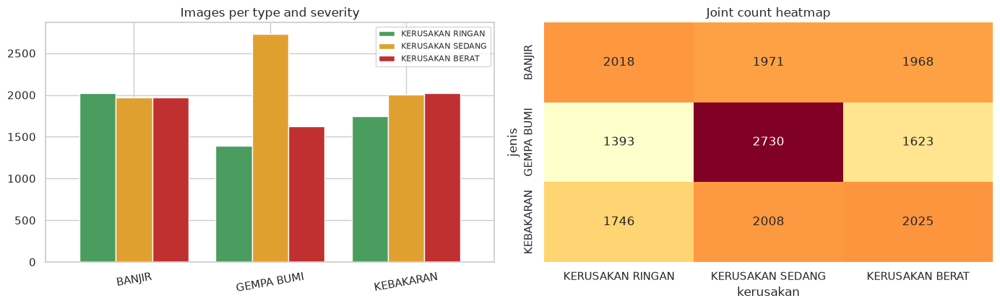

In [10]:
grid = pd.crosstab(train_df.jenis, train_df.kerusakan).reindex(
    index=CFG.JENIS, columns=CFG.KERUSAKAN)
imbalance = grid.values.max() / grid.values.min()

print(grid.to_string())
print()
print('jenis totals    :', grid.sum(axis=1).to_dict())
print('kerusakan totals:', grid.sum(axis=0).to_dict())
print(f'imbalance ratio : {imbalance:.2f}x')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
grid.plot(kind='bar', ax=ax[0], rot=10, width=0.8,
          color=['#4a9d5f', '#e0a030', '#c03030'])
ax[0].set_title('Images per type and severity')
ax[0].set_xlabel('')
ax[0].legend(fontsize=8)
sns.heatmap(grid, annot=True, fmt='d', cmap='YlOrRd', ax=ax[1], cbar=False)
ax[1].set_title('Joint count heatmap')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'eda_class_balance.png', dpi=130)
plt.show()

#### Insights

> Sembilan sel merentang dari 1.393 sampai 2.730 citra, rasio 1,96 kali. Rentang itu cukup landai sehingga pembobotan kelas atau pengambilan sampel ulang akan menambah ragam lebih besar daripada yang dipulihkannya. Karena itu fungsi kerugian dibiarkan tanpa bobot dan pembagian data cukup distratifikasi pada label sembilan arah.

> Marginalnya bahkan lebih rata: ketiga jenis bencana berselisih dalam 4% satu sama lain, dan ketiga tingkat kerusakan dalam 30%. Karena metrik memberi bobot sama pada kedua tugas, tidak ada pembobotan ulang yang diterapkan pada kedua kepala.

---

## Resolusi dan Rasio Aspek

Ukuran masukan yang disuapkan ke *backbone* hanya bermakna relatif terhadap apa yang sebenarnya dibawa citra sumber. Bila sebagian besar citra lebih kecil daripada resolusi model, jalur pemrosesan sedang menaikkan skala derau, dan masukan yang lebih kecil akan sama akuratnya sekaligus lebih cepat.

TRAIN: median 788x512, min-side median 500, AR median 1.334
    min-side < 224:   1.6%
    min-side < 384:  19.5%
    min-side < 512:  50.6%
TEST: median 800x600, min-side median 600, AR median 1.333
    min-side < 224:   0.9%
    min-side < 384:  20.2%
    min-side < 512:  28.7%

distinct exact resolutions in train: 3909


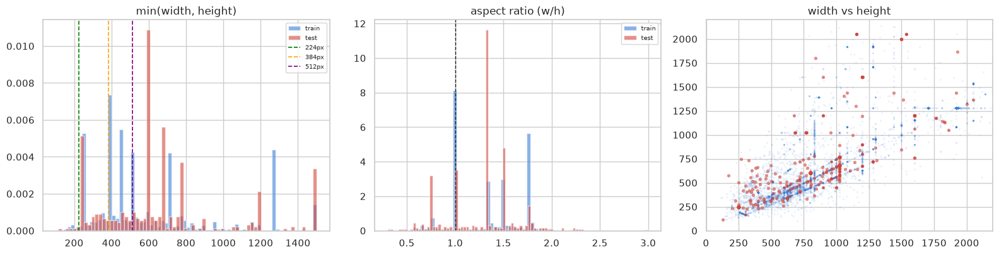

In [11]:
for name, d in [('TRAIN', train_df), ('TEST', test_df)]:
    print(f'{name}: median {int(d.w.median())}x{int(d.h.median())}, '
          f'min-side median {int(d.minside.median())}, '
          f'AR median {d.ar.median():.3f}')
    for thr in (224, 384, 512):
        print(f'    min-side < {thr}: {(d.minside < thr).mean() * 100:5.1f}%')
print()
print('distinct exact resolutions in train:', train_df.groupby(["w", "h"]).ngroups)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for d, lab, col in [(train_df, 'train', '#3b7dd8'), (test_df, 'test', '#d1453b')]:
    ax[0].hist(d.minside.clip(0, 1500), bins=70, alpha=0.6, density=True, label=lab, color=col)
    ax[1].hist(d.ar.clip(0, 3), bins=70, alpha=0.6, density=True, label=lab, color=col)
for v, col in [(224, 'green'), (384, 'orange'), (512, 'purple')]:
    ax[0].axvline(v, ls='--', lw=1.2, color=col, label=f'{v}px')
ax[0].set_title('min(width, height)')
ax[0].legend(fontsize=7)
ax[1].axvline(1.0, ls='--', color='k', lw=1)
ax[1].set_title('aspect ratio (w/h)')
ax[1].legend(fontsize=7)
ax[2].scatter(train_df.w, train_df.h, s=2, alpha=0.06, color='#3b7dd8')
ax[2].scatter(test_df.w, test_df.h, s=8, alpha=0.5, color='#d1453b')
ax[2].set_xlim(0, 2200)
ax[2].set_ylim(0, 2200)
ax[2].set_title('width vs height')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'eda_resolution.png', dpi=130)
plt.show()

#### Insights

> Latih dan uji bertumpang tindih rapat pada sisi terpendek maupun rasio aspek, sehingga transformasi yang ditala pada data latih berpindah ke data uji tanpa pergeseran domain pada geometri. Median rasio aspek adalah 1,33 pada kedua sisi, yaitu foto web 4:3 yang klasik.

> Hanya sekitar 1,6% citra latih yang sisi pendeknya di bawah 224 piksel dan 20% di bawah 384, sehingga masukan 384 piksel merupakan detail sejati bagi empat dari lima citra, bukan hasil interpolasi. Mendorongnya jauh melewati 512 mulai menaikkan skala mayoritas korpus, yang membeli ongkos tanpa informasi.

---

## Format dan Mode Warna

Empat format wadah dan empat mode warna muncul dalam korpus. Subbagian ini mengukurnya karena satu saja citra beralfa atau berpalet yang lolos tanpa konversi sampai ke fungsi *collate* akan menghasilkan galat jumlah kanal jauh di dalam pelatihan.

In [12]:
for name, d in [('TRAIN', train_df), ('TEST', test_df)]:
    print(f'{name} fmt : {d.fmt.value_counts().to_dict()}')
    print(f'{name} mode: {d["mode"].value_counts().to_dict()}')

non_rgb = train_df[train_df['mode'] != 'RGB']
print()
print(f'non-RGB train images: {len(non_rgb)} ({len(non_rgb) / len(train_df) * 100:.2f}%)')
if len(non_rgb):
    print()
    print(pd.crosstab(non_rgb['mode'], non_rgb.jenis).to_string())

TRAIN fmt : {'JPEG': 11723, 'PNG': 5746, 'WEBP': 11, 'MPO': 2}
TRAIN mode: {'RGB': 16709, 'RGBA': 771, 'P': 1, 'CMYK': 1}
TEST fmt : {'JPEG': 396, 'PNG': 54}
TEST mode: {'RGB': 395, 'RGBA': 54, 'L': 1}

non-RGB train images: 773 (4.42%)

jenis  BANJIR  GEMPA BUMI
mode                     
CMYK        0           1
P           0           1
RGBA        7         764


#### Insights

> Sekitar 4,4% citra latih bukan RGB polos, dan yang membawa alfa hampir seluruhnya terkonsentrasi pada satu jenis bencana. Konversi dengan `.convert('RGB')` saja memetakan piksel transparan menjadi hitam, yang memproduksi wilayah gelap luas yang berkorelasi dengan kelas tersebut. Bagian 5 justru mengomposit alfa ke atas putih.

> Konsentrasi itu adalah tanda pertama dari pola yang lebih luas: setiap sel kelas dikumpulkan dari himpunan sumbernya sendiri, sehingga metadata tingkat wadah membawa informasi kelas yang tidak dibawa pikselnya. Subbagian berikutnya mengukur seberapa besar.

---

## Audit Jalan Pintas Metadata

Sebuah *gradient-boosted tree* dilatih hanya atas metadata berkas, tanpa satu piksel pun dibaca. Bila resolusi dan ukuran bita sanggup memulihkan label, korpusnya berkorelasi kelas dan model apa pun bebas mempelajari jalan pintas itu alih-alih bencananya sendiri. Angka ini penting karena menetapkan harapan tentang bagaimana model berbasis piksel akan berperilaku.

In [13]:
meta_X = pd.DataFrame({
    'w': train_df.w, 'h': train_df.h, 'ar': train_df.ar,
    'mp': train_df.w * train_df.h, 'bytes': train_df.bytes,
    'bpp': train_df.bytes / (train_df.w * train_df.h),
    'is_png': (train_df.fmt == 'PNG').astype(int),
    'is_rgba': (train_df['mode'] == 'RGBA').astype(int),
})

meta_scores = {}
for target, name in [(train_df.jenis, 'jenis'), (train_df.kerusakan, 'kerusakan')]:
    scores = cross_val_score(
        HistGradientBoostingClassifier(max_iter=120, random_state=CFG.SEED),
        meta_X, target, cv=StratifiedKFold(5, shuffle=True, random_state=CFG.SEED),
        scoring='accuracy')
    meta_scores[name] = scores.mean()
    print(f'metadata-only accuracy on {name:10s}: {scores.mean():.4f} '
          f'(chance 0.3333, majority {target.value_counts(normalize=True).max():.4f})')
print()
print(f'implied metadata-only micro F1: {np.mean(list(meta_scores.values())):.4f}')

metadata-only accuracy on jenis     : 0.9147 (chance 0.3333, majority 0.3408)
metadata-only accuracy on kerusakan : 0.6673 (chance 0.3333, majority 0.3838)

implied metadata-only micro F1: 0.7910


#### Insights

> Metadata berkas saja memulihkan jenis bencana dengan akurasi sekitar 91% dan tingkat kerusakan sekitar 67%, tersirat micro F1 mendekati 0,79 tanpa menengok satu piksel pun. Citra untuk setiap sel kelas dikumpulkan dari sumber berbeda dengan resolusi dan pengodean yang berbeda pula.

---

## Statistik Warna per Kelas

Sebuah sampel citra direduksi menjadi sepuluh deskriptor aras rendah. Tujuannya bukan membangun pengklasifikasi dari deskriptor itu, melainkan mengetahui augmentasi mana yang aman: bila sebuah statistik kanal memisahkan kelas dengan kuat, augmentasi yang mengacaknya sedang merusak sinyal alih-alih menambah keinvarianan.

colour stats:   0%|          | 0/1800 [00:00<?, ?it/s]

between-class separation, in units of overall standard deviation
           by_jenis  by_kerusakan
B             1.128         0.435
sat           1.122         0.562
edge          1.114         0.242
warm          1.102         0.428
G             0.961         0.265
dark_frac     0.835         0.236
bright        0.515         0.136
blow_frac     0.412         0.215
contrast      0.405         0.110
R             0.354         0.133


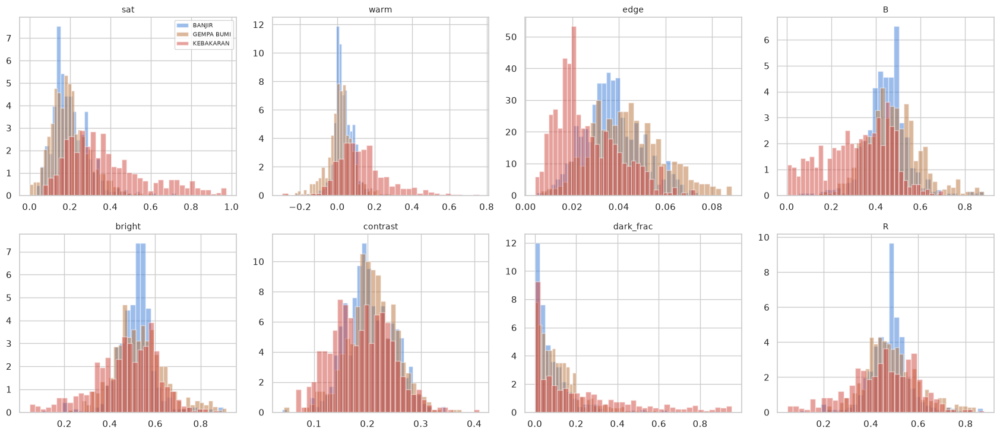

In [14]:
def colour_stats(path):
    try:
        with Image.open(path) as im:
            a = np.asarray(im.convert('RGB').resize((160, 160), Image.BILINEAR), np.float32) / 255.0
    except Exception:
        return None
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    mx, mn = a.max(-1), a.min(-1)
    gray = 0.299 * r + 0.587 * g + 0.114 * b
    gx = np.abs(np.diff(gray, axis=1)).mean()
    gy = np.abs(np.diff(gray, axis=0)).mean()
    return {
        'R': r.mean(), 'G': g.mean(), 'B': b.mean(),
        'bright': mx.mean(), 'sat': np.where(mx > 1e-6, (mx - mn) / (mx + 1e-6), 0.0).mean(),
        'contrast': gray.std(), 'edge': (gx + gy) / 2, 'warm': r.mean() - b.mean(),
        'dark_frac': float((gray < 0.18).mean()), 'blow_frac': float((gray > 0.92).mean()),
    }


stat_sample = train_df.groupby('cls9', group_keys=False).sample(
    n=min(200, train_df.cls9.value_counts().min()), random_state=CFG.SEED)
with ThreadPoolExecutor(max_workers=CFG.NUM_PROBE_WORKERS) as ex:
    raw = list(tqdm(ex.map(colour_stats, stat_sample.path.tolist()),
                    total=len(stat_sample), desc='colour stats'))
keep = [i for i, s in enumerate(raw) if s is not None]
stats = pd.DataFrame([raw[i] for i in keep])
stats['jenis'] = stat_sample.jenis.values[keep]
stats['kerusakan'] = stat_sample.kerusakan.values[keep]

feat_cols = ['R', 'G', 'B', 'bright', 'sat', 'contrast', 'edge', 'warm', 'dark_frac', 'blow_frac']
sep = pd.DataFrame({
    'by_jenis': (stats.groupby('jenis')[feat_cols].mean().max()
                 - stats.groupby('jenis')[feat_cols].mean().min()) / stats[feat_cols].std(),
    'by_kerusakan': (stats.groupby('kerusakan')[feat_cols].mean().max()
                     - stats.groupby('kerusakan')[feat_cols].mean().min()) / stats[feat_cols].std(),
}).sort_values('by_jenis', ascending=False)
print('between-class separation, in units of overall standard deviation')
print(sep.round(3).to_string())

fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, col in zip(axes.ravel(), ['sat', 'warm', 'edge', 'B', 'bright', 'contrast', 'dark_frac', 'R']):
    for j, colour in zip(CFG.JENIS, ['#3b7dd8', '#b8733a', '#d1453b']):
        ax.hist(stats.loc[stats.jenis == j, col], bins=35, alpha=0.5, density=True,
                label=j, color=colour)
    ax.set_title(col, fontsize=10)
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'eda_colour_stats.png', dpi=130)
plt.show()

#### Insights

> Saturasi, kehangatan dan kerapatan tepi masing-masing memisahkan ketiga jenis bencana lebih dari satu simpangan baku. Kebakaran bersifat hangat, jenuh dan gelap; banjir kurang jenuh dan halus; gempa bumi kelabu dengan energi tepi tinggi dari puing. Warna karenanya merupakan petunjuk aras rendah paling kuat bagi `jenis`, dan *hue jitter* adalah satu-satunya augmentasi yang sanggup menghapusnya. Karena alasan itu bagian 5 membatasi *hue* pada 0,02.

> Tingkat kerusakan terpisah jauh lebih lemah pada setiap deskriptor warna. Ia hidup pada struktur dan tata letak adegan, bukan pada palet: bangunan utuh dan bangunan runtuh berbagi kelabu beton yang sama. Kepala itu karenanya memerlukan resolusi dan konteks global, yang menuntut lantai skala tinggi pada pemotongan acak agar keseluruhan adegan tetap selamat.

---

## Kisi Contoh

Pemeriksaan visual atas apa yang sebenarnya dimuat kesembilan kelas. Membaca segelintir contoh per sel menyingkap konvensi pelabelan yang tidak diungkap statistik ringkasan mana pun.

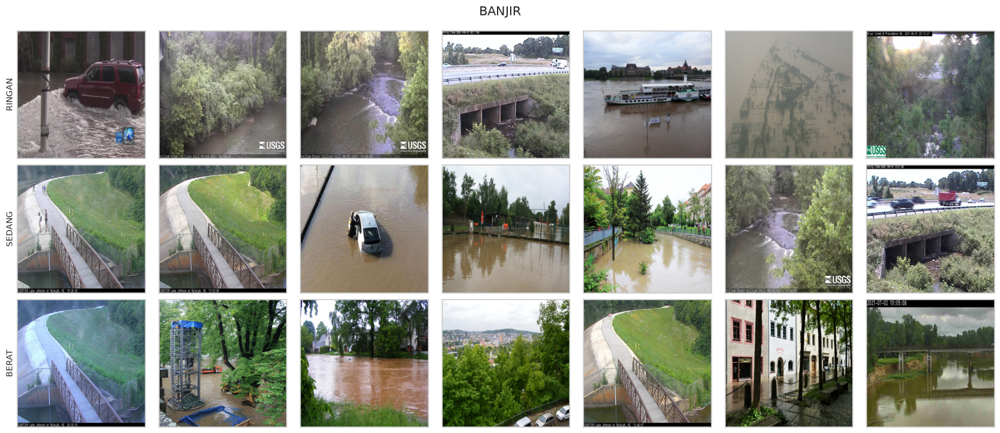

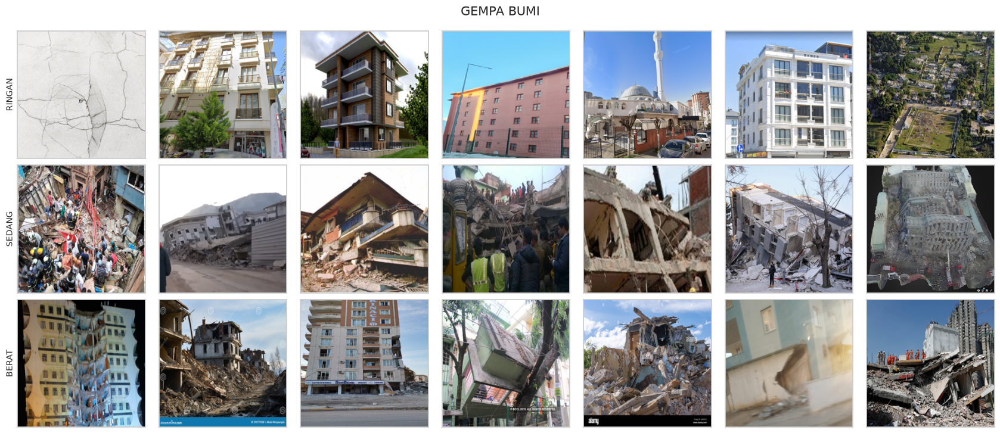

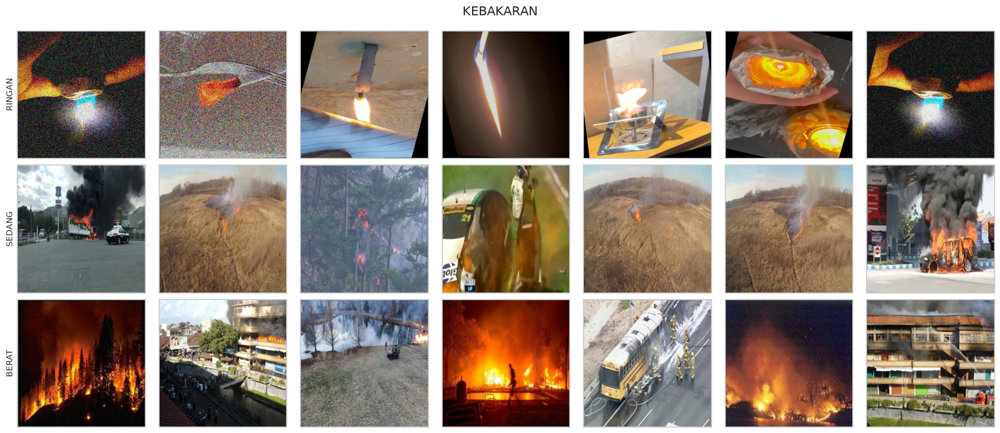

In [15]:
for j in CFG.JENIS:
    fig, axes = plt.subplots(3, 7, figsize=(17, 7.4))
    for r, k in enumerate(CFG.KERUSAKAN):
        sub = train_df[(train_df.jenis == j) & (train_df.kerusakan == k)].sample(
            7, random_state=CFG.SEED)
        for col, (_, row) in enumerate(sub.iterrows()):
            try:
                with Image.open(row.path) as im:
                    axes[r, col].imshow(im.convert('RGB').resize((240, 240)))
            except Exception:
                pass
            axes[r, col].set_xticks([])
            axes[r, col].set_yticks([])
        axes[r, 0].set_ylabel(k.replace('KERUSAKAN ', ''), fontsize=10)
    fig.suptitle(j, fontsize=15)
    plt.tight_layout()
    plt.savefig(CFG.FIG_DIR / f'eda_samples_{j.replace(" ", "_")}.png', dpi=110)
    plt.show()

#### Insights

> Sumbu kerusakan bermakna berbeda pada setiap jenis bencana. Pada gempa bumi ia adalah keadaan fisik bangunan, dari utuh dengan retak rambut, melalui runtuh sebagian, sampai puing sepenuhnya. Pada kebakaran ia adalah skala nyala, dari api lilin atau pemantik, melalui kebakaran ilalang, sampai kebakaran hutan penuh. Pada banjir ia adalah tinggi muka air terhadap acuan tetap. Satu kepala kerusakan harus mempelajari tiga gagasan berbeda sekaligus, terkondisi pada jenisnya. Itulah sebabnya model di bawah mempertahankan kepala gabungan sembilan arah di samping dua kepala marginal.

> Banyak citra banjir merupakan bingkai dari kamera sungai USGS yang terpasang tetap, dan kamera yang sama muncul pada beberapa tingkat kerusakan. Adegan yang sama karenanya membawa label berbeda, dan bingkai yang nyaris identik tersebar di seluruh korpus. Bagian 4 mengukurnya secara langsung karena hal itu menentukan apakah angka validasi dapat dipercaya.

> Sebagian citra kelas kebakaran paling ringan yang kasatmata sudah dirotasi dengan sudut hitam berlapis dan membawa derau piksel yang disuntikkan, artinya panitia mengaugmentasi sel itu secara luring untuk menambal cacahnya. Menumpuk satu rotasi berlapis lagi di atasnya akan melipatgandakan artefak tersebut, sehingga bagian 5 memakai rotasi tanpa batas hitam.

---

## Sumbunya Berurut, Softmax-nya Tidak

Peringkat kerusakan adalah kuantitas berurut: RINGAN, SEDANG, lalu BERAT. Kepala kategoris tidak mengetahui urutan itu, dan konsekuensinya menentukan sebagian besar rancangan di bawah.

*Softmax* atas tiga kategori tak berurut tidak punya cara menyatakan *di antara RINGAN dan SEDANG*. Ketika buktinya memang berada di tengah, jawaban yang meminimalkan kerugian adalah kelas yang bertetangga dengan keduanya, sehingga ketidakpastian dan peringkat tengah menjadi prediksi yang sama. Itu sifat parameterisasinya, bukan sifat *backbone*-nya, dan menambah kapasitas tidak akan menyentuhnya.

---

## Kerusakan Adalah Tiga Masalah Berbeda yang Mengenakan Satu Label

Banjir disebut berat ketika muka airnya tinggi, kebakaran ketika luas hangusnya lebar, gempa bumi ketika strukturnya sudah runtuh. Satu kepala tiga arah harus meletakkan satu batas keputusan yang bermakna ketiga hal itu sekaligus.

In [16]:
ct = pd.crosstab(train_df.jenis, train_df.kerusakan)[CFG.KERUSAKAN]
pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
print(ct.to_string())
print()
print(pct.to_string())
print()
print('A type-blind severity head must fit all three of these rows with one boundary.')
gm = pct.loc['GEMPA BUMI', 'KERUSAKAN SEDANG']
bj = pct.loc['BANJIR', 'KERUSAKAN SEDANG']
print(f'GEMPA BUMI is {gm:.0f}% SEDANG against {bj:.0f}% for BANJIR.')

kerusakan   KERUSAKAN RINGAN  KERUSAKAN SEDANG  KERUSAKAN BERAT
jenis                                                          
BANJIR                  2018              1971             1968
GEMPA BUMI              1393              2730             1623
KEBAKARAN               1746              2008             2025

kerusakan   KERUSAKAN RINGAN  KERUSAKAN SEDANG  KERUSAKAN BERAT
jenis                                                          
BANJIR                  33.9              33.1             33.0
GEMPA BUMI              24.2              47.5             28.2
KEBAKARAN               30.2              34.7             35.0

A type-blind severity head must fit all three of these rows with one boundary.
GEMPA BUMI is 48% SEDANG against 33% for BANJIR.


#### Insights

> Sumbu kerusakan berurut sementara *softmax* tiga arah tidak, sehingga ketidakpastian dan peringkat tengah menjadi prediksi yang sama. Sebuah kepala yang ragu antara RINGAN dan SEDANG akan menjawab SEDANG, bukan karena ia melihat SEDANG, melainkan karena itulah satu-satunya jawaban yang bertetangga dengan keduanya.

> Dua konsekuensi rancangan langsung mengikuti: target kerusakan seharusnya membawa jarak peringkat alih-alih berbentuk *one-hot*, dan kepala kerusakan seharusnya mengetahui bencana apa yang sedang dipandangnya alih-alih merata-ratakan satu batas atas tiga tata letak. Bagian 4 memasok konsekuensi ketiga, begitu pengelompokan adegan tersedia.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Rancangan Validasi <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Kisi contoh memperlihatkan bahwa korpus memuat banyak bingkai nyaris identik, sehingga bagian ini mengukur duplikasi tersebut secara langsung, lalu membangun pembagian data yang menahan setiap salinan satu adegan pada satu sisi pagar. Salah pada titik ini adalah kekeliruan termahal yang tersedia di sini.

## Audit Duplikat Persis dan Nyaris Persis

Citra dikelompokkan lewat komponen terhubung atas jarak Hamming antar *difference hash* miliknya. Jarak paling banyak enam bit dari 64 sepadan dengan adegan yang sama dengan satu perubahan kecil, seperti pengodean ulang, pemotongan tipis, atau bingkai video yang sedikit berbeda.

hamming:   0%|          | 0/9 [00:00<?, ?it/s]

scene groups            : 12,553 for 17,932 images
images in a multi-image group: 6,853 (38.2%)
largest group           : 596 images
exact-hash redundant train copies: 2,122 (12.14%)

multi-image train groups          : 1,448
  spanning more than one jenis    : 8
  spanning more than one kerusakan: 161

test images sharing a scene group with train: 29/450 (6.4%)


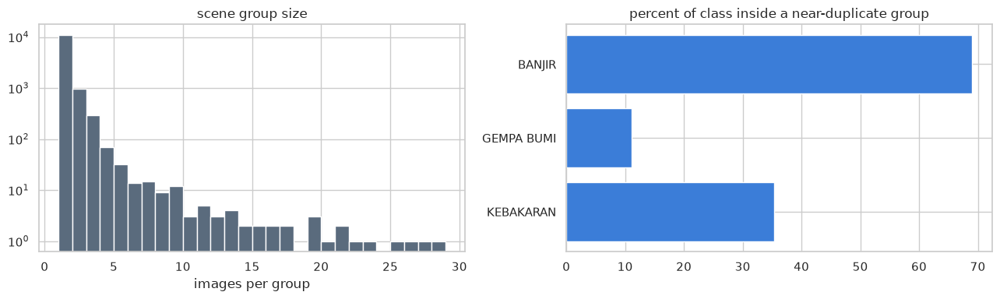

In [17]:
def hashes_to_bits(hex_series):
    v = np.array([int(h, 16) for h in hex_series], dtype=np.uint64)
    return np.unpackbits(v.view(np.uint8).reshape(-1, 8)[:, ::-1], axis=1)


def group_by_hamming(bits, threshold):
    n = len(bits)
    parent = np.arange(n)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    chunk = 2048
    for start in tqdm(range(0, n, chunk), desc='hamming'):
        block = bits[start:start + chunk]
        dist = (block[:, None, :] != bits[None, :, :]).sum(-1)
        ii, jj = np.where(dist <= threshold)
        for a, b in zip(ii + start, jj):
            a, b = int(a), int(b)
            if a < b:
                ra, rb = find(a), find(b)
                if ra != rb:
                    parent[max(ra, rb)] = min(ra, rb)
    return np.array([find(i) for i in range(n)])


all_hashes = pd.concat([train_df.dhash, test_df.dhash], ignore_index=True)
bits = hashes_to_bits(all_hashes).astype(np.int8)
groups = group_by_hamming(bits, CFG.HAMMING_THRESHOLD)
train_df['group'] = groups[:len(train_df)]
test_df['group'] = groups[len(train_df):]

sizes = pd.Series(groups).value_counts()
multi = sizes[sizes > 1]
exact_dup = train_df.dhash.value_counts()
exact_extra = int((exact_dup[exact_dup > 1] - 1).sum())

print(f'scene groups            : {len(sizes):,} for {len(groups):,} images')
print(f'images in a multi-image group: {int(multi.sum()):,} '
      f'({multi.sum() / len(groups) * 100:.1f}%)')
print(f'largest group           : {int(sizes.max())} images')
print(f'exact-hash redundant train copies: {exact_extra:,} '
      f'({exact_extra / len(train_df) * 100:.2f}%)')

span = train_df.groupby('group').agg(n=('path', 'size'), nj=('jenis', 'nunique'),
                                     nk=('kerusakan', 'nunique'))
span = span[span.n > 1]
print()
print(f'multi-image train groups          : {len(span):,}')
print(f'  spanning more than one jenis    : {int((span.nj > 1).sum()):,}')
print(f'  spanning more than one kerusakan: {int((span.nk > 1).sum()):,}')

leak = test_df[test_df.group.isin(set(train_df.group))]
print()
print(f'test images sharing a scene group with train: {len(leak)}/{len(test_df)} '
      f'({len(leak) / len(test_df) * 100:.1f}%)')

share = (train_df[train_df.group.isin(span.index)].groupby('jenis').size()
         / train_df.groupby('jenis').size() * 100)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(sizes.values, bins=np.arange(1, 30), color='#5a6b7d')
ax[0].set_yscale('log')
ax[0].set_title('scene group size')
ax[0].set_xlabel('images per group')
ax[1].barh(range(len(share)), share.values, color='#3b7dd8')
ax[1].set_yticks(range(len(share)), share.index)
ax[1].invert_yaxis()
ax[1].set_title('percent of class inside a near-duplicate group')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'eda_duplicates.png', dpi=130)
plt.show()

#### Insights

> Sekitar 38% dari seluruh citra berada dalam kelompok yang memuat setidaknya satu kembaran nyaris identik, dan kelompok tunggal terbesar menampung ratusan bingkai. Kelas banjir paling parah terdampak pada kisaran 69%, yang cocok dengan bingkai kamera tetap yang terlihat pada kisi contoh. Pembagian acak akan menempatkan kembaran dari sebagian besar citra validasi ke dalam himpunan latih.

> Lebih dari seratus kelompok memuat adegan sama yang diarsipkan di bawah dua label kerusakan berbeda. Itu derau label yang tidak dapat direduksi: tidak ada model yang bisa benar pada kedua salinan. Keadaan ini membatasi skor yang dapat dicapai, dan menjadi alasan fungsi kerugian di bawah memakai *label smoothing* dan target lunak alih-alih berupaya mencocoki setiap label secara persis.

---

## Pengelompokan Citra Hasil Rotasi dan Pencerminan

*Difference hash* dapat melewatkan duplikat yang telah dirotasi atau diberi derau kuat. Tahap ini melengkapi pengelompokan awal agar citra dari adegan yang sama tidak tersebar ke data pelatihan dan validasi.

Pengelompokan dilakukan melalui tiga langkah:

1. **Pencarian kandidat.** Citra diubah ke koordinat polar, kemudian diringkas menggunakan magnitudo Fourier dan statistik warna untuk membentuk deskriptor yang tahan terhadap rotasi dan pencerminan.
2. **Verifikasi pasangan.** Kandidat diperiksa menggunakan korelasi citra polar pada berbagai rotasi dan pencerminan. Pasangan dengan skor di atas `CFG.REGROUP_NCC` digabungkan ke dalam kelompok yang sama.
3. **Pemeriksaan pencerminan horizontal.** Duplikat hasil pencerminan juga dicari melalui transformasi *difference hash*, tanpa membaca ulang citra.

Pengelompokan ini memprioritaskan pencegahan kebocoran data akibat duplikat yang masuk ke fold berbeda.


In [18]:
if not getattr(CFG, 'USE_INVARIANT_REGROUP', False):
    print('invariant regrouping disabled (CFG.USE_INVARIANT_REGROUP)')
else:
    POLAR_R = getattr(CFG, 'REGROUP_POLAR_R', 16)
    POLAR_A = getattr(CFG, 'REGROUP_POLAR_A', 64)
    POLAR_H = 10
    _rad = (np.arange(POLAR_R) + 0.5) / POLAR_R * 0.97
    _ang = np.arange(POLAR_A) / POLAR_A * 2 * np.pi
    _py = _rad[:, None] * np.sin(_ang[None, :])
    _px = _rad[:, None] * np.cos(_ang[None, :])

    def polar_sample(path, size=96):
        im = Image.open(path)
        try:
            im.draft('RGB', (size * 3, size * 3))
        except Exception:
            pass
        if im.mode in ('RGBA', 'LA', 'P'):
            im = im.convert('RGBA')
            im = Image.alpha_composite(
                Image.new('RGBA', im.size, (255, 255, 255, 255)), im)
        im = im.convert('RGB')
        w, h = im.size
        s = int(min(w, h) * 0.70)
        im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
        a = np.asarray(im.resize((size, size), Image.BILINEAR), np.float32) / 255.0
        yy = ((_py + 1) * 0.5 * (size - 1)).astype(np.int32)
        xx = ((_px + 1) * 0.5 * (size - 1)).astype(np.int32)
        p = a[yy, xx]
        g = p @ np.array([0.299, 0.587, 0.114], np.float32)
        g = (np.roll(g, 1, 1) + g + np.roll(g, -1, 1)) / 3.0   # blunt pixel grain
        return g, p.mean(1), p.std(1)

    def polar_safe(path):
        try:
            return polar_sample(path)
        except Exception:
            return (np.zeros((POLAR_R, POLAR_A), np.float32),
                    np.zeros((POLAR_R, 3), np.float32),
                    np.zeros((POLAR_R, 3), np.float32))

    all_paths = train_df.path.tolist() + test_df.path.tolist()
    with ThreadPoolExecutor(max_workers=CFG.NUM_PROBE_WORKERS) as ex:
        polar = list(tqdm(ex.map(polar_safe, all_paths), total=len(all_paths),
                          desc='polar resample'))
    n_all = len(polar)
    G = np.stack([p[0] for p in polar])
    ring_mean = np.stack([p[1] for p in polar]).reshape(n_all, -1)
    ring_std = np.stack([p[2] for p in polar]).reshape(n_all, -1)
    del polar

    mag = np.abs(np.fft.rfft(G - G.mean(2, keepdims=True), axis=2))
    desc = np.concatenate([mag[:, :, :POLAR_H].reshape(n_all, -1),
                           ring_mean * 3, ring_std * 3], axis=1).astype(np.float32)
    desc /= np.linalg.norm(desc, axis=1, keepdims=True) + 1e-8

    Z = G - G.mean((1, 2), keepdims=True)
    Z /= Z.reshape(n_all, -1).std(1).reshape(-1, 1, 1) + 1e-6
    F_fwd = np.fft.rfft(Z, axis=2)
    F_mir = np.fft.rfft(Z[:, :, ::-1], axis=2)
    del G, Z, mag

    def best_rotated_ncc(i, j):
        """Highest correlation over every rotation offset and both mirrorings."""
        best = -1.0
        for Fj in (F_fwd[j], F_mir[j]):
            cc = np.fft.irfft(F_fwd[i] * np.conj(Fj), n=POLAR_A, axis=1)
            best = max(best, float(cc.sum(0).max()) / (POLAR_R * POLAR_A))
        return best

    topk = int(min(getattr(CFG, 'REGROUP_TOPK', 16), n_all - 1))
    proposed = set()
    for start in tqdm(range(0, n_all, 512), desc='candidates'):
        sim = desc[start:start + 512] @ desc.T
        for r in range(len(sim)):
            sim[r, start + r] = -1.0
        idx = np.argpartition(-sim, topk, axis=1)[:, :topk]
        val = np.take_along_axis(sim, idx, axis=1)
        rr, kk = np.where(val > CFG.REGROUP_COS)
        for a, b in zip(rr, kk):
            i, j = start + int(a), int(idx[a, b])
            if i != j:
                proposed.add((min(i, j), max(i, j)))

    verified = [(i, j) for i, j in sorted(proposed)
                if best_rotated_ncc(i, j) > CFG.REGROUP_NCC]

    mirror_bits = 1 - bits.reshape(n_all, 8, 8)[:, :, ::-1].reshape(n_all, 64)
    B_up = bits.astype(np.float32)
    B_mir = mirror_bits.astype(np.float32)
    up_norm = B_up.sum(1)
    mirrored = set()
    for start in tqdm(range(0, n_all, 1024), desc='mirror hashes'):
        blk = B_mir[start:start + 1024]
        dist = blk.sum(1)[:, None] + up_norm[None, :] - 2.0 * (blk @ B_up.T)
        rr, cc_ = np.where(dist <= CFG.HAMMING_THRESHOLD)
        for a, b in zip(rr + start, cc_):
            i, j = int(a), int(b)
            if i != j:
                mirrored.add((min(i, j), max(i, j)))

    parent = np.arange(n_all)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[max(ra, rb)] = min(ra, rb)

    order = np.argsort(groups, kind='stable')       # seed with the hash groups
    for k in range(1, n_all):
        if groups[order[k]] == groups[order[k - 1]]:
            union(int(order[k]), int(order[k - 1]))
    for i, j in verified:
        union(i, j)
    for i, j in mirrored:
        union(i, j)
    groups_before = groups.copy()
    groups = np.array([find(i) for i in range(n_all)])
    train_df['group'] = groups[:len(train_df)]
    test_df['group'] = groups[len(train_df):]

    def _stats(g):
        s = pd.Series(g).value_counts()
        return len(s), int(s.max()), float(s[s > 1].sum()) / len(g) * 100

    b_n, b_max, b_multi = _stats(groups_before)
    a_n, a_max, a_multi = _stats(groups)
    print()
    print(f'descriptor proposals            : {len(proposed):,}')
    print(f'  verified by rotation search   : {len(verified):,} '
          f'(NCC > {CFG.REGROUP_NCC})')
    print(f'mirrored-hash pairs             : {len(mirrored):,}')
    print()
    print(f'{"":<26}{"hash only":>12}{"invariant":>12}')
    print(f'{"scene groups":<26}{b_n:>12,}{a_n:>12,}')
    print(f'{"largest group":<26}{b_max:>12,}{a_max:>12,}')
    print(f'{"% in a multi-image group":<26}{b_multi:>12.1f}{a_multi:>12.1f}')
    print()
    merged_hash_groups = b_n - a_n
    print(f'hash groups absorbed into a larger one: {merged_hash_groups:,}')
    leak_before = test_df.assign(g=groups_before[len(train_df):]).g.isin(
        set(groups_before[:len(train_df)])).sum()
    leak_after = test_df.group.isin(set(train_df.group)).sum()
    print(f'test images sharing a group with train: {leak_before} -> {leak_after}')
    del desc, F_fwd, F_mir

polar resample:   0%|          | 0/17932 [00:00<?, ?it/s]

candidates:   0%|          | 0/36 [00:00<?, ?it/s]

mirror hashes:   0%|          | 0/18 [00:00<?, ?it/s]


descriptor proposals            : 120,458
  verified by rotation search   : 33,967 (NCC > 0.9)
mirrored-hash pairs             : 1,528

                             hash only   invariant
scene groups                    12,553      10,890
largest group                      596       1,370
% in a multi-image group          38.2        47.5

hash groups absorbed into a larger one: 1,663
test images sharing a group with train: 29 -> 36


#### Insights

> Setiap pasangan yang digabungkan tahap ini adalah pasangan yang sebelumnya sudah dinyatakan tak berkerabat oleh pengelompokan *hash*, sehingga masing-masing bebas mengangkangi batas lipatan. Cacahnya adalah besar kebocoran yang selama ini dibawa pembagian data.

> Penggabungan itu tidak gratis. Menyerap kelompok satu ke dalam lainnya menaikkan ukuran kelompok terbesar dan membuat lipatan menjadi kurang merata, karena `StratifiedGroupKFold` harus menempatkan blok tak terbagi yang lebih besar di suatu tempat. Tabel lipatan yang dicetak di bawah memperlihatkan ongkosnya. Ini pertukaran yang tepat: lipatan tak merata memberi taksiran yang lebih berderau, lipatan bocor memberi taksiran yang salah.

---

## Pembagian Berkelompok dan Terstratifikasi

`StratifiedGroupKFold` menahan setiap anggota satu kelompok adegan di dalam lipatan yang sama, sambil menyeimbangkan sebaran kelas sembilan arah antar lipatan sejauh pengelompokan mengizinkan. Lipatan nol dipakai sebagai himpunan validasi secara bawaan; `CFG.RUN_ALL_FOLDS` mengalihkannya ke proses validasi silang penuh.

In [19]:
sgkf = StratifiedGroupKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
train_df['fold'] = -1
for fold, (_, val_idx) in enumerate(sgkf.split(train_df, train_df.cls9, train_df.group)):
    train_df.loc[train_df.index[val_idx], 'fold'] = fold

print(pd.crosstab(train_df.fold, train_df.cls9).to_string())
print()

for fold in range(CFG.N_FOLDS):
    tr_g = set(train_df.loc[train_df.fold != fold, 'group'])
    va_g = set(train_df.loc[train_df.fold == fold, 'group'])
    assert not (tr_g & va_g), f'group leak in fold {fold}'
print('verified: no scene group appears on both sides of any fold')

naive = train_df.sample(frac=1.0, random_state=CFG.SEED)
naive_val = naive.iloc[:len(train_df) // CFG.N_FOLDS]
naive_tr_groups = set(naive.iloc[len(train_df) // CFG.N_FOLDS:].group)
leaked = naive_val.group.isin(naive_tr_groups).mean()
print(f'a naive random split would leak {leaked * 100:.1f}% of its validation rows')

train_df.to_csv(CFG.OUTPUT_DIR / 'train_manifest.csv', index=False)
test_df.to_csv(CFG.OUTPUT_DIR / 'test_manifest.csv', index=False)

cls9  BANJIR | KERUSAKAN BERAT  BANJIR | KERUSAKAN RINGAN  BANJIR | KERUSAKAN SEDANG  GEMPA BUMI | KERUSAKAN BERAT  GEMPA BUMI | KERUSAKAN RINGAN  GEMPA BUMI | KERUSAKAN SEDANG  KEBAKARAN | KERUSAKAN BERAT  KEBAKARAN | KERUSAKAN RINGAN  KEBAKARAN | KERUSAKAN SEDANG
fold                                                                                                                                                                                                                                                                     
0                          393                        404                        394                           325                            279                            546                          405                           349                           402
1                          394                        403                        394                           325                            278                            546                          

#### Insights

> Pembagian berkelompok menyingkirkan kebocoran yang akan dibawa pembagian acak pada kira-kira sepertiga baris validasinya. 

---

## Seberapa Banyak Sisa Galat Kerusakan yang Dapat Dijangkau

In [20]:
train_df['k_idx'] = train_df.kerusakan.map(CFG.KERUSAKAN_TO_IDX)


def majority_ceiling(df, key):
    return sum(v.value_counts().iloc[0] for _, v in df.groupby(key)['k_idx']) / len(df)


rows = {}
for label, key in [('exact duplicate (dHash)', 'dhash'),
                   (f'scene group (Hamming<={CFG.HAMMING_THRESHOLD})', 'group')]:
    nunique = train_df.groupby(key)['k_idx'].transform('nunique')
    rows[label] = dict(ceiling=majority_ceiling(train_df, key),
                       images_affected=int((nunique > 1).sum()),
                       pct=float((nunique > 1).mean() * 100))
print(pd.DataFrame(rows).T.round(4).to_string())

SCENE_CEILING = rows[f'scene group (Hamming<={CFG.HAMMING_THRESHOLD})']['ceiling']
print()
print(f'langit mayoritas per adegan   : {SCENE_CEILING:.4f}')

                          ceiling  images_affected      pct
exact duplicate (dHash)    0.9902            379.0   2.1679
scene group (Hamming<=6)   0.9267           3396.0  19.4257

langit mayoritas per adegan   : 0.9267


---

## Analisis Perbedaan Anotasi

Perbedaan label dalam kelompok adegan yang sama digunakan untuk memperkirakan pola derau pelabelan. Analisis ini menghitung seberapa sering suatu tingkat kerusakan diberi label sebagai tingkat lain.

Setiap adegan diberi bobot yang sama agar hasil tidak didominasi kelompok dengan banyak citra. Jika seluruh pasangan citra dihitung langsung, sepuluh kelompok terbesar menyumbang 96% pasangan. Dengan pembobotan per adegan, nilai diagonal matriks meningkat dari 0,51 menjadi 0,90, sehingga target lunak yang dihasilkan lebih mendekati label *one-hot*.


1,445 multi-image scenes contribute one unit of evidence each
Q = P(a second annotation of the same scene is the column | the first is the row)
        RINGAN  SEDANG   BERAT
RINGAN  0.8970  0.0845  0.0185
SEDANG  0.0468  0.8727  0.0806
BERAT   0.0131  0.1027  0.8842

disagreement one rank away : 91%
disagreement two ranks away: 9%
mean diagonal, how far the label is trusted: 0.8846


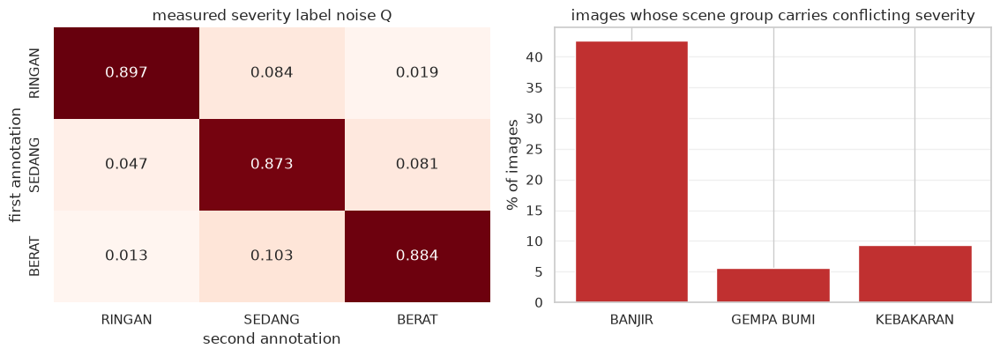


jenis
BANJIR        42.6
GEMPA BUMI     5.6
KEBAKARAN      9.3


In [ ]:
pair_counts = np.zeros((3, 3), dtype=np.float64)
n_scenes = 0
for _, sub in train_df.groupby('group')['k_idx']:
    if len(sub) < 2:
        continue
    counts = np.bincount(sub.to_numpy(), minlength=3).astype(float)
    pairs = np.outer(counts, counts) - np.diag(counts)
    if pairs.sum() > 0:
        pair_counts += pairs / pairs.sum()
        n_scenes += 1
print(f'{n_scenes:,} multi-image scenes contribute one unit of evidence each')

row_sums = pair_counts.sum(axis=1, keepdims=True)
NOISE_Q = np.where(row_sums > 0, pair_counts / np.maximum(row_sums, 1), np.eye(3))
short = [k.replace('KERUSAKAN ', '') for k in CFG.KERUSAKAN]
print('Q = P(a second annotation of the same scene is the column | the first is the row)')
print(pd.DataFrame(NOISE_Q, index=short, columns=short).round(4).to_string())
print()
off = NOISE_Q - np.diag(np.diag(NOISE_Q))
adjacent = off[0, 1] + off[1, 0] + off[1, 2] + off[2, 1]
extreme = off[0, 2] + off[2, 0]
print(f'disagreement one rank away : {adjacent / (adjacent + extreme) * 100:.0f}%')
print(f'disagreement two ranks away: {extreme / (adjacent + extreme) * 100:.0f}%')
print(f'mean diagonal, how far the label is trusted: {np.diag(NOISE_Q).mean():.4f}')

train_df['sev_conflict'] = train_df.groupby('group')['k_idx'].transform('nunique') > 1
conflict_pct = train_df.groupby('jenis')['sev_conflict'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
sns.heatmap(NOISE_Q, annot=True, fmt='.3f', cmap='Reds', cbar=False, ax=axes[0],
            xticklabels=short, yticklabels=short)
axes[0].set_title('measured severity label noise Q')
axes[0].set_xlabel('second annotation')
axes[0].set_ylabel('first annotation')
axes[1].bar(conflict_pct.index, conflict_pct.values, color='#c03030')
axes[1].set_ylabel('% of images')
axes[1].set_title('images whose scene group carries conflicting severity')
axes[1].grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'sev_label_noise.png', dpi=130)
plt.show()
print()
print(conflict_pct.round(1).to_string())

#### Insights

> Langitnya bukan 0,77. Menjawab setiap kelompok adegan dengan label mayoritasnya sendiri mencetak skor jauh di atas 0,90, sehingga sebagian besar dari selisih 23 poin itu dapat dijangkau alih-alih tidak dapat direduksi.

> Perselisihan itu juga sangat tidak merata antar jenis bencana, dan ia menumpuk pada jenis yang oleh analisis data eksploratif sudah ditunjukkan sebagian besar berupa rekaman kamera tetap. Itulah argumen ketiga untuk mengondisikan kepala kerusakan pada jenis alih-alih merata-ratakannya.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Preprocessing<a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Pemuatan Citra Kanonis

Orientasi EXIF, kanal alfa dan mode palet dinormalkan saat pemuatan. Alfa dikomposit ke atas putih alih-alih dibuang, karena membuangnya memetakan wilayah transparan menjadi hitam, sementara analisis data eksploratif menemukan citra beralfa menumpuk pada satu kelas.

In [ ]:
def load_canonical(path):
    im = Image.open(path)
    im = ImageOps.exif_transpose(im)
    if im.mode in ('RGBA', 'LA', 'P'):
        im = im.convert('RGBA')
        bg = Image.new('RGBA', im.size, (255, 255, 255, 255))
        im = Image.alpha_composite(bg, im)
    return im.convert('RGB')


class RotateInscribedCrop(nn.Module):
    def __init__(self, max_deg: float = 10.0):
        super().__init__()
        self.max_deg = max_deg

    @staticmethod
    def inscribed(w, h, angle):
        a = abs(math.radians(angle))
        long_side, short_side = (w, h) if w >= h else (h, w)
        cos_a, sin_a = abs(math.cos(a)), abs(math.sin(a))
        if long_side * sin_a <= short_side * cos_a:
            denom = cos_a * cos_a - sin_a * sin_a
            if abs(denom) < 1e-6:
                wr, hr = long_side / 2, short_side / 2
            else:
                wr = (long_side * cos_a - short_side * sin_a) / denom
                hr = (short_side * cos_a - long_side * sin_a) / denom
        else:
            half = short_side / (2 * sin_a) if sin_a > 1e-6 else short_side
            wr, hr = 2 * half * cos_a, 2 * half * sin_a
        return (wr, hr) if w >= h else (hr, wr)

    def forward(self, img):
        angle = random.uniform(-self.max_deg, self.max_deg)
        w, h = img.size
        rotated = img.rotate(angle, resample=Image.BICUBIC, expand=False)
        cw, ch = self.inscribed(w, h, angle)
        return TF.center_crop(rotated, [max(8, int(ch)), max(8, int(cw))])


class AddSensorNoise(nn.Module):

    def __init__(self, sigma_min: float = 0.01, sigma_max: float = 0.05):
        super().__init__()
        self.sigma_min, self.sigma_max = sigma_min, sigma_max

    def forward(self, x):
        sigma = random.uniform(self.sigma_min, self.sigma_max)
        return (x + torch.randn_like(x) * sigma).clamp(0.0, 1.0)


probe_paths = []
for j in CFG.JENIS:
    probe_paths.append(train_df[train_df.jenis == j].sample(1, random_state=3).iloc[0])
for subset in [train_df[train_df['mode'] == 'RGBA'],
               train_df[train_df.ar < 0.6],
               train_df[train_df.ar > 2.2]]:
    if len(subset):
        probe_paths.append(subset.sample(1, random_state=1).iloc[0])
print(f'{len(probe_paths)} probe images selected, including the awkward aspect ratios')

6 probe images selected, including the awkward aspect ratios


In [23]:
DTYPE_KW = 'dtype' if int(transformers.__version__.split('.')[0]) >= 5 else 'torch_dtype'

processor = AutoImageProcessor.from_pretrained(CFG.MODEL_ID, token=CFG.HF_TOKEN)
IMG_MEAN = tuple(processor.image_mean)
IMG_STD = tuple(processor.image_std)

print('processor    :', type(processor).__name__)
print('image_mean   :', IMG_MEAN)
print('image_std    :', IMG_STD)
print('processor size:', getattr(processor, 'size', None))
print()
print(f'CFG.IMAGE_SIZE = {CFG.IMAGE_SIZE}, patch multiple = {CFG.PATCH_MULTIPLE}, '
      f'patch grid = {CFG.IMAGE_SIZE // CFG.PATCH_MULTIPLE} x '
      f'{CFG.IMAGE_SIZE // CFG.PATCH_MULTIPLE}')
assert CFG.IMAGE_SIZE % CFG.PATCH_MULTIPLE == 0, 'input size must be a multiple of the patch size'
print('verified: normalisation taken from the backbone processor, input size '
      'compatible with the patch grid')

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

processor    : DINOv3ViTImageProcessor
image_mean   : (0.485, 0.456, 0.406)
image_std    : (0.229, 0.224, 0.225)
processor size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None)

CFG.IMAGE_SIZE = 384, patch multiple = 16, patch grid = 24 x 24
verified: normalisation taken from the backbone processor, input size compatible with the patch grid


---

## Evaluation Display

Evaluasi pada data validasi dan uji menggunakan citra utuh yang diubah ukurannya menjadi persegi `IMAGE_SIZE`, tanpa pemotongan. Pendekatan ini mempertahankan seluruh area citra, termasuk bukti kerusakan di bagian tepi yang dapat hilang akibat *center crop*, meskipun rasio aspek berubah.

Agar model terbiasa dengan tampilan tersebut, 35% sampel pelatihan menggunakan transformasi bingkai penuh melalui `CFG.P_FULL_FRAME`. Sisanya menggunakan `RandomResizedCrop`, dengan pemilihan transformasi melalui `RandomChoice`.

Panel berikut membandingkan kedua tampilan pada citra berasio aspek paling lebar untuk memperlihatkan area yang terpotong.

train transform
Compose(
      RandomApply(    RotateInscribedCrop())
      RandomChoice(transforms=[RandomResizedCrop(size=(384, 384), scale=(0.65, 1.0), ratio=(0.8, 1.25), interpolation=InterpolationMode.BILINEAR, antialias=True), Resize(size=[384, 384], interpolation=InterpolationMode.BILINEAR, antialias=True)], p=[0.65, 0.35])
      RandomHorizontalFlip(p=0.5)
      RandomApply(    ColorJitter(brightness=(0.75, 1.25), contrast=(0.75, 1.25), saturation=(0.8, 1.2), hue=(-0.02, 0.02)))
      ToImage()
      ToDtype(scale=True)
      RandomApply(    AddSensorNoise())
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
      RandomErasing(p=0.1, scale=(0.02, 0.12), ratio=(0.3, 3.3), value=[0.0], inplace=False)
)

eval transform (full frame)
Compose(
      Resize(size=[384, 384], interpolation=InterpolationMode.BILINEAR, antialias=True)
      ToImage()
      ToDtype(scale=True)
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplac

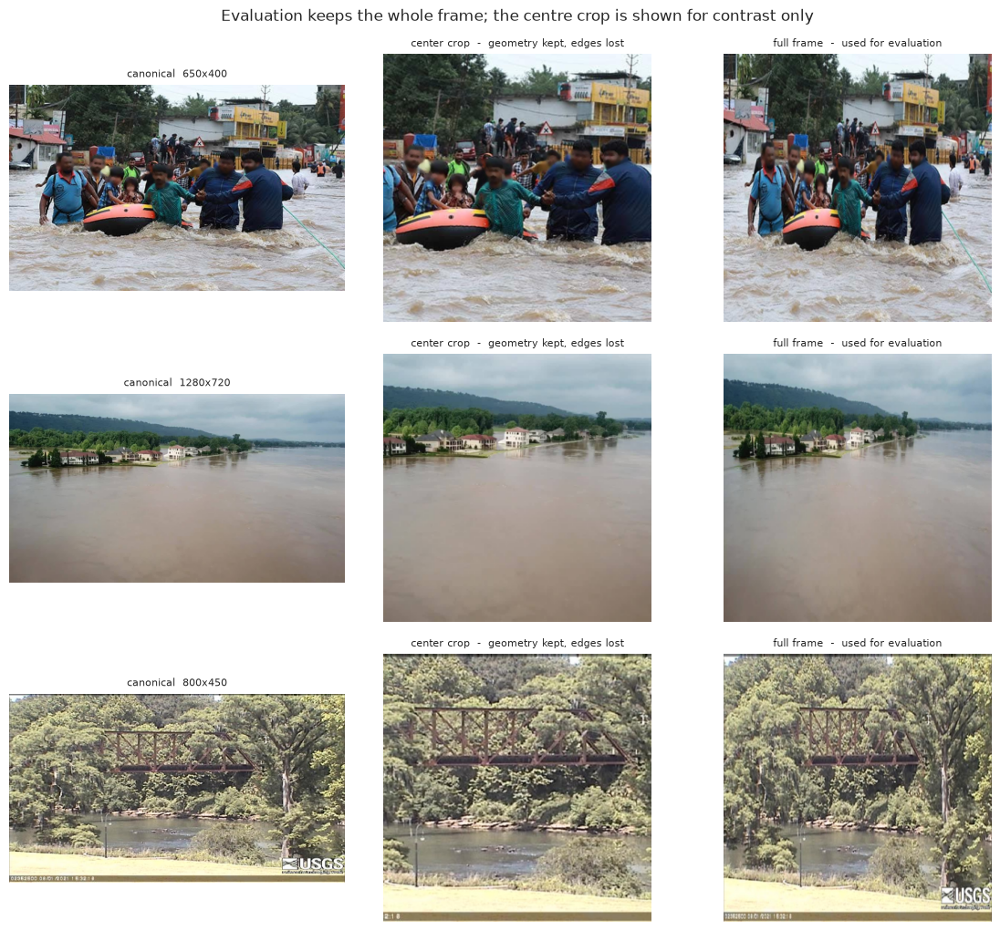

In [24]:
def eval_transform(size, view='full'):
    if view == 'full':
        geom = [T.Resize((size, size), antialias=True)]
    elif view == 'center':
        geom = [T.Resize(size, antialias=True), T.CenterCrop(size)]
    else:
        raise ValueError(view)
    return T.Compose(geom + [
        T.ToImage(),
        T.ToDtype(torch.float32, scale=True),
        T.Normalize(IMG_MEAN, IMG_STD),
    ])


train_tf = T.Compose([
    T.RandomApply([RotateInscribedCrop(CFG.ROTATE_DEG)], p=CFG.P_ROTATE),
    T.RandomChoice([
        T.RandomResizedCrop(CFG.IMAGE_SIZE, scale=CFG.CROP_SCALE, ratio=(0.80, 1.25),
                            antialias=True),
        T.Resize((CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), antialias=True),
    ], p=[1 - CFG.P_FULL_FRAME, CFG.P_FULL_FRAME]),
    T.RandomHorizontalFlip(0.5),
    T.RandomApply([T.ColorJitter(*CFG.COLOR_JITTER)], p=CFG.P_JITTER),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.RandomApply([AddSensorNoise(*CFG.NOISE_SIGMA)], p=CFG.P_NOISE),
    T.Normalize(IMG_MEAN, IMG_STD),
    T.RandomErasing(p=CFG.P_ERASE, scale=(0.02, 0.12), value=0),
])

eval_tf = eval_transform(CFG.IMAGE_SIZE, 'full')

print('train transform');  print(train_tf)
print();  print('eval transform (full frame)');  print(eval_tf)

def denorm(t):
    x = t.float() * torch.tensor(IMG_STD).view(3, 1, 1) + torch.tensor(IMG_MEAN).view(3, 1, 1)
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


wide = train_df[train_df.ar > 1.6].sample(3, random_state=7)
fig, axes = plt.subplots(3, 3, figsize=(11.5, 10.4))
for r, (_, row) in enumerate(wide.iterrows()):
    img = load_canonical(row.path)
    axes[r, 0].imshow(img)
    axes[r, 0].set_title(f'canonical  {img.size[0]}x{img.size[1]}', fontsize=8)
    axes[r, 1].imshow(denorm(eval_transform(CFG.IMAGE_SIZE, 'center')(img)))
    axes[r, 1].set_title('center crop  -  geometry kept, edges lost', fontsize=8)
    axes[r, 2].imshow(denorm(eval_transform(CFG.IMAGE_SIZE, 'full')(img)))
    axes[r, 2].set_title('full frame  -  used for evaluation', fontsize=8)
for ax in axes.ravel():
    ax.axis('off')
fig.suptitle('Evaluation keeps the whole frame; the centre crop is shown for '
             'contrast only', fontsize=12)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'prep_eval_views.png', dpi=120)
plt.show()

---

## Random Erasing

`RandomErasing` menghapus area persegi panjang secara acak sebagai regularisasi. Karena augmentasi ini dapat menghilangkan bukti kerusakan tanpa mengubah label, probabilitas penerapannya dibatasi menjadi 0,10. Panel berikut memperlihatkan contoh ketika area kerusakan ikut terhapus.


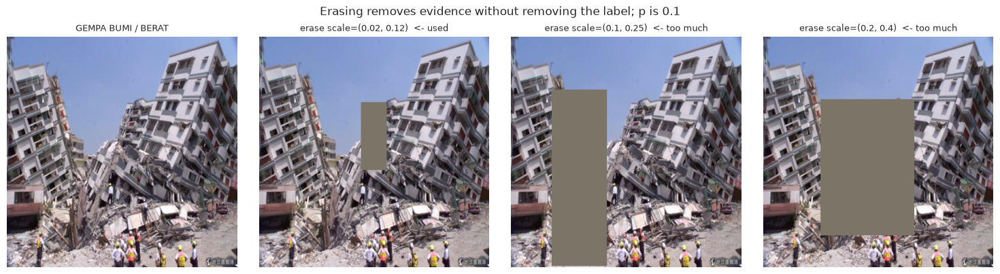

In [25]:
sev = train_df[train_df.kerusakan == 'KERUSAKAN BERAT'].sample(1, random_state=11).iloc[0]
sev_img = load_canonical(sev.path)
base = T.Compose([T.Resize((CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), antialias=True),
                  T.ToImage(), T.ToDtype(torch.float32, scale=True),
                  T.Normalize(IMG_MEAN, IMG_STD)])(sev_img)
fig, axes = plt.subplots(1, 4, figsize=(15, 4.1))
axes[0].imshow(denorm(base))
axes[0].set_title(f'{sev.jenis} / BERAT', fontsize=9)
for i, scale in enumerate([(0.02, 0.12), (0.10, 0.25), (0.20, 0.40)], start=1):
    torch.manual_seed(4 + i)
    axes[i].imshow(denorm(T.RandomErasing(p=1.0, scale=scale, value=0)(base.clone())))
    axes[i].set_title(f'erase scale={scale}' + ('  <- used' if i == 1 else '  <- too much'),
                      fontsize=9)
for ax in axes:
    ax.axis('off')
fig.suptitle('Erasing removes evidence without removing the label; '
             f'p is {CFG.P_ERASE}', fontsize=12)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'prep_erasing.png', dpi=120)
plt.show()

---

## Noise

Tingkat derau citra diperkirakan dari residu pada 8% blok paling datar berukuran 16 × 16 piksel. Pemilihan area datar membantu mengurangi pengaruh tekstur objek terhadap estimasi.

Hasil analisis menunjukkan bahwa salah satu kombinasi jenis dan kerusakan memiliki tingkat derau lebih dari sepuluh kali kombinasi lainnya. Untuk mengurangi risiko model menggunakan derau sebagai petunjuk label, derau Gaussian ditambahkan dengan probabilitas yang sama pada seluruh kelas.

`CFG.P_NOISE` mengatur probabilitas penerapan, sedangkan `CFG.NOISE_SIGMA` mengatur rentang kekuatan derau pada skala piksel [0, 1]. Nilai 0,05 setara dengan sekitar 13 pada skala 0–255.


grain train:   0%|          | 0/720 [00:00<?, ?it/s]

grain test:   0%|          | 0/450 [00:00<?, ?it/s]

                                n  median    p90  pct_grainy
cls9                                                        
BANJIR | KERUSAKAN BERAT       80    0.30   0.88        0.00
BANJIR | KERUSAKAN RINGAN      80    0.30   0.51        0.00
BANJIR | KERUSAKAN SEDANG      80    0.25   0.59        0.00
GEMPA BUMI | KERUSAKAN BERAT   80    0.09   0.61        1.25
GEMPA BUMI | KERUSAKAN RINGAN  80    0.10   0.69        3.75
GEMPA BUMI | KERUSAKAN SEDANG  80    0.20   0.85        2.50
KEBAKARAN | KERUSAKAN BERAT    80    0.13   0.76        7.50
KEBAKARAN | KERUSAKAN RINGAN   80    0.10  38.58       36.25
KEBAKARAN | KERUSAKAN SEDANG   80    0.17   0.36        0.00

evaluation set, share above the same threshold: 0.4%
training set overall                          : 5.7%


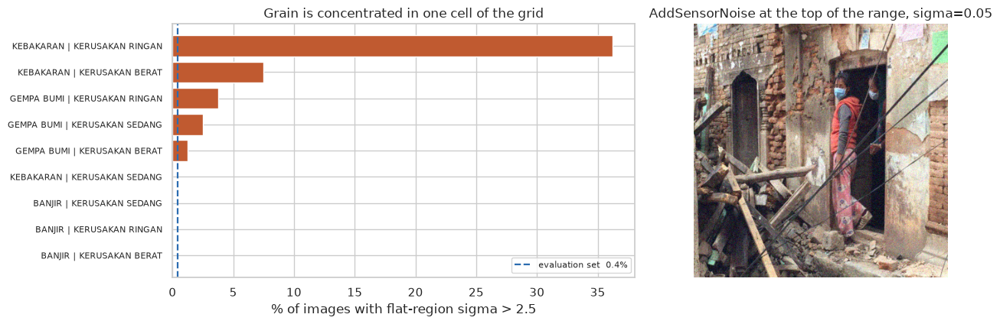

In [ ]:
def flat_region_sigma(path, block=16, flat_frac=0.08):
    try:
        g = np.asarray(load_canonical(path).convert('L'), np.float32)
    except Exception:
        return np.nan
    h, w = g.shape
    hh, ww = (h // block) * block, (w // block) * block
    if hh < block * 4 or ww < block * 4:
        return np.nan
    blocks = (g[:hh, :ww].reshape(hh // block, block, ww // block, block)
              .transpose(0, 2, 1, 3).reshape(-1, block, block))
    keep = max(4, int(len(blocks) * flat_frac))
    sel = blocks[np.argsort(blocks.reshape(len(blocks), -1).std(1))[:keep]]
    lap = (sel[:, :-2, :-2] - 2 * sel[:, 1:-1, :-2] + sel[:, 2:, :-2]
           - 2 * sel[:, :-2, 1:-1] + 4 * sel[:, 1:-1, 1:-1] - 2 * sel[:, 2:, 1:-1]
           + sel[:, :-2, 2:] - 2 * sel[:, 1:-1, 2:] + sel[:, 2:, 2:])
    return float(np.sqrt(np.pi / 2) * np.abs(lap).mean() / 6.0)


NOISE_SAMPLE = 80
noise_rows = pd.concat(
    [s.sample(min(len(s), NOISE_SAMPLE), random_state=CFG.SEED)
     for _, s in train_df.groupby('cls9')]).reset_index(drop=True)
with ThreadPoolExecutor(max_workers=CFG.NUM_PROBE_WORKERS) as ex:
    tr_sigma = list(tqdm(ex.map(flat_region_sigma, noise_rows.path.tolist()),
                         total=len(noise_rows), desc='grain train'))
    te_sigma = list(tqdm(ex.map(flat_region_sigma, test_df.path.tolist()),
                         total=len(test_df), desc='grain test'))
noise_rows = noise_rows.assign(sigma=tr_sigma)

GRAIN_THRESHOLD = 2.5      # levels of 255; ordinary photographs sit far below
grain = noise_rows.groupby('cls9').sigma.agg(
    n='size', median='median',
    p90=lambda s: s.quantile(0.90),
    pct_grainy=lambda s: 100 * (s > GRAIN_THRESHOLD).mean())
te_grain = 100 * (pd.Series(te_sigma) > GRAIN_THRESHOLD).mean()

print(grain.round(2).to_string())
print()
print(f'evaluation set, share above the same threshold: {te_grain:.1f}%')
print(f'training set overall                          : {100 * (noise_rows.sigma > GRAIN_THRESHOLD).mean():.1f}%')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
order = grain.sort_values('pct_grainy')
ax[0].barh(range(len(order)), order.pct_grainy.values, color='#c05a30')
ax[0].axvline(te_grain, color='#2b6cb0', ls='--', lw=1.6,
              label=f'evaluation set  {te_grain:.1f}%')
ax[0].set_yticks(range(len(order)), order.index, fontsize=8)
ax[0].set_xlabel(f'% of images with flat-region sigma > {GRAIN_THRESHOLD}')
ax[0].set_title('Grain is concentrated in one cell of the grid')
ax[0].legend(fontsize=8)
_demo = load_canonical(noise_rows.sample(1, random_state=3).iloc[0].path)
_base = T.Compose([T.Resize((CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), antialias=True),
                   T.ToImage(), T.ToDtype(torch.float32, scale=True)])(_demo)
torch.manual_seed(0)
ax[1].imshow(AddSensorNoise(CFG.NOISE_SIGMA[1], CFG.NOISE_SIGMA[1])(_base)
             .permute(1, 2, 0).numpy())
ax[1].set_title(f'AddSensorNoise at the top of the range, sigma={CFG.NOISE_SIGMA[1]}')
ax[1].axis('off')
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'prep_sensor_noise.png', dpi=130)
plt.show()

---

## Strategi Pencampuran

Pelatihan menggunakan **MixUp tanpa CutMix**. Pencampuran label berdasarkan luas area pada CutMix belum tentu sesuai dengan tingkat kerusakan, karena indikatornya berbeda antarjenis bencana, seperti keruntuhan bangunan dan tinggi muka air.

Ablasi selama pengembangan menunjukkan bahwa penggunaan MixUp saja meningkatkan skor sebesar 0,002 pada epos terbaik dan 0,006 pada epos terakhir. Karena itu, `CFG.P_CUTMIX_WITHIN_MIX` ditetapkan menjadi nol.

CutMix tetap tersedia untuk pengujian ablasi dengan mengubah konfigurasi tersebut. Aturan target kerusakannya diatur melalui `CFG.CUTMIX_SEVERITY_RULE`.


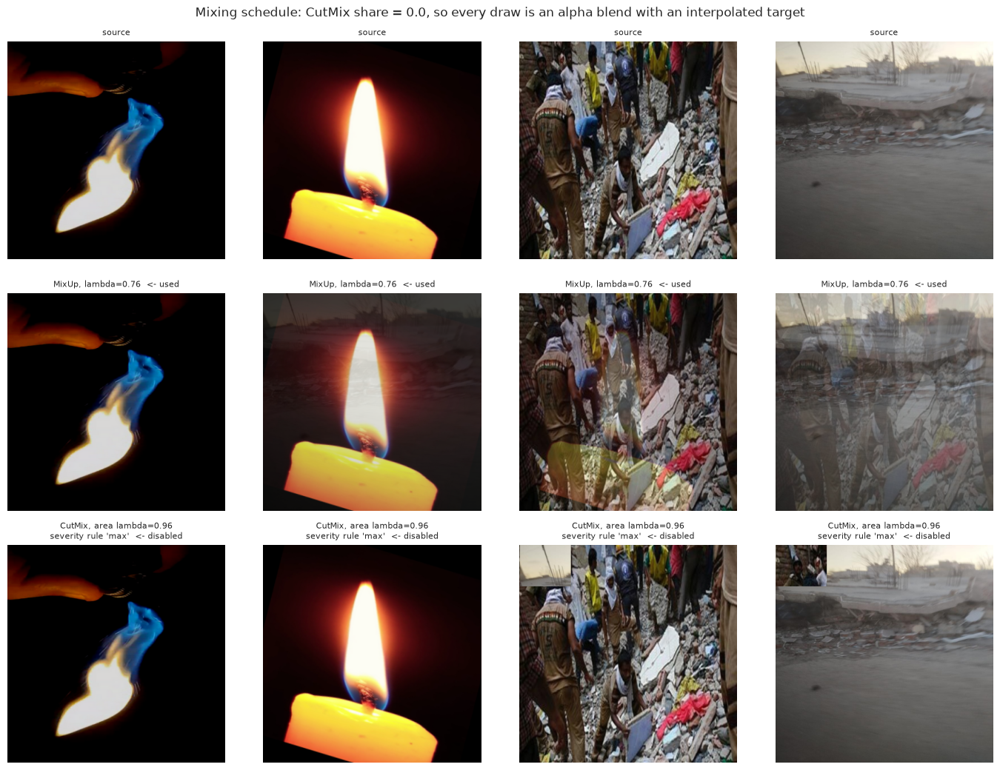

In [27]:
def mix_batch(x, p_mix, alpha_mixup, alpha_cutmix):
    """Returns x, perm, lam_area, kind. kind is 'none' | 'mixup' | 'cutmix'."""
    if random.random() > p_mix:
        return x, None, 1.0, 'none'
    perm = torch.randperm(x.size(0), device=x.device)
    if random.random() >= CFG.P_CUTMIX_WITHIN_MIX:
        lam = float(np.random.beta(alpha_mixup, alpha_mixup))
        return lam * x + (1.0 - lam) * x[perm], perm, lam, 'mixup'
    lam = float(np.random.beta(alpha_cutmix, alpha_cutmix))
    _, _, h, w = x.shape
    cut_h, cut_w = int(h * math.sqrt(1 - lam)), int(w * math.sqrt(1 - lam))
    cy, cx = random.randrange(h), random.randrange(w)
    y1, y2 = max(cy - cut_h // 2, 0), min(cy + cut_h // 2, h)
    x1, x2 = max(cx - cut_w // 2, 0), min(cx + cut_w // 2, w)
    x[:, :, y1:y2, x1:x2] = x[perm, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / (h * w))
    return x, perm, lam, 'cutmix'


def severity_mix_targets(yk, perm, lam, kind):
    """(target_a, target_b, weight_a) for the severity head under mixing."""
    if perm is None:
        return yk, yk, 1.0
    if kind == 'cutmix' and CFG.CUTMIX_SEVERITY_RULE == 'max':
        worse = torch.maximum(yk, yk[perm])
        return worse, worse, 1.0
    return yk, yk[perm], lam


_probe = torch.stack([
    T.Compose([T.Resize((CFG.IMAGE_SIZE, CFG.IMAGE_SIZE), antialias=True), T.ToImage(),
               T.ToDtype(torch.float32, scale=True), T.Normalize(IMG_MEAN, IMG_STD)])(
        load_canonical(p))
    for p in train_df.sample(4, random_state=5).path])
_saved_cut = CFG.P_CUTMIX_WITHIN_MIX
random.seed(2); np.random.seed(2); torch.manual_seed(2)
CFG.P_CUTMIX_WITHIN_MIX = 1.0      # force each branch so both can be shown
cm_x, cm_perm, cm_lam, cm_kind = mix_batch(_probe.clone(), 1.0, 0.2, 1.0)
CFG.P_CUTMIX_WITHIN_MIX = 0.0
mx_x, mx_perm, mx_lam, mx_kind = mix_batch(_probe.clone(), 1.0, 0.2, 1.0)
CFG.P_CUTMIX_WITHIN_MIX = _saved_cut
assert cm_kind == 'cutmix' and mx_kind == 'mixup'

used, unused = ('  <- used', '  <- disabled') if CFG.P_CUTMIX_WITHIN_MIX == 0 else \
               ('', '')
fig, axes = plt.subplots(3, 4, figsize=(14, 10.6))
for i in range(4):
    axes[0, i].imshow(denorm(_probe[i]))
    axes[0, i].set_title('source', fontsize=8)
    axes[1, i].imshow(denorm(mx_x[i]))
    axes[1, i].set_title(f'MixUp, lambda={mx_lam:.2f}{used}', fontsize=8)
    axes[2, i].imshow(denorm(cm_x[i]))
    axes[2, i].set_title(f'CutMix, area lambda={cm_lam:.2f}\n'
                         f"severity rule '{CFG.CUTMIX_SEVERITY_RULE}'{unused}", fontsize=8)
for ax in axes.ravel():
    ax.axis('off')
fig.suptitle(f'Mixing schedule: CutMix share = {CFG.P_CUTMIX_WITHIN_MIX}, '
             'so every draw is an alpha blend with an interpolated target', fontsize=12)
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'prep_cutmix_severity.png', dpi=120)
plt.show()

---

## Rangkaian Pipeline dan Dataset

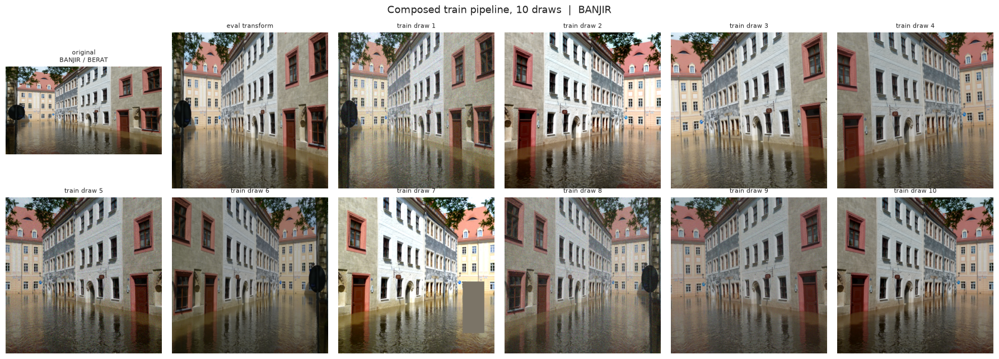

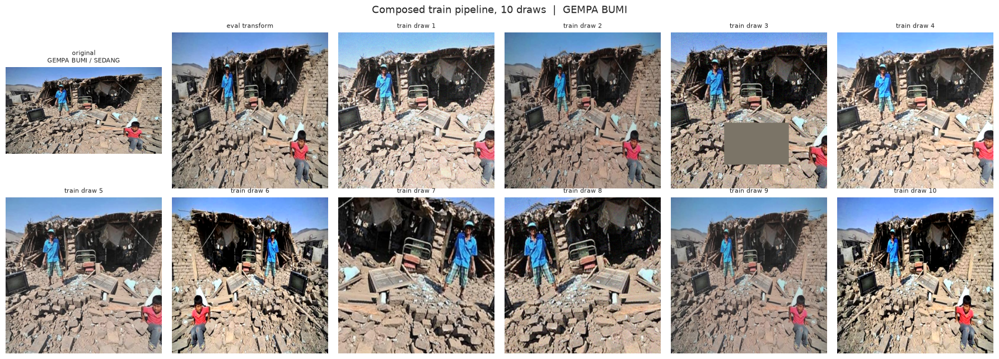

In [28]:
for row in probe_paths[:2]:
    img = load_canonical(row.path)
    fig, axes = plt.subplots(2, 6, figsize=(18, 6.6))
    axes[0, 0].imshow(img)
    axes[0, 0].set_title(f"original\n{row.jenis} / "
                         f"{row.kerusakan.replace('KERUSAKAN ', '')}", fontsize=8)
    axes[0, 1].imshow(denorm(eval_tf(img)))
    axes[0, 1].set_title('eval transform', fontsize=8)
    for i in range(10):
        r, col = divmod(i + 2, 6)
        axes[r, col].imshow(denorm(train_tf(img)))
        axes[r, col].set_title(f'train draw {i + 1}', fontsize=8)
    for ax in axes.ravel():
        ax.axis('off')
    fig.suptitle(f'Composed train pipeline, 10 draws  |  {row.jenis}', fontsize=13)
    plt.tight_layout()
    plt.savefig(CFG.FIG_DIR /
                f'prep_pipeline_{row.jenis.replace(" ", "_")}.png', dpi=115)
    plt.show()

In [30]:
class DisasterDataset(Dataset):
    def __init__(self, df, transform, has_labels=True):
        self.paths = df.path.tolist()
        self.transform = transform
        self.has_labels = has_labels
        if has_labels:
            self.y_j = df.jenis.map(CFG.JENIS_TO_IDX).to_numpy()
            self.y_k = df.kerusakan.map(CFG.KERUSAKAN_TO_IDX).to_numpy()
            self.y_9 = self.y_j * 3 + self.y_k

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        x = self.transform(load_canonical(self.paths[i]))
        if not self.has_labels:
            return x, 0, 0, 0
        return x, int(self.y_9[i]), int(self.y_j[i]), int(self.y_k[i])


def make_loaders(fold):
    if CFG.TRAIN_ON_ALL:
        tr = train_df.reset_index(drop=True)
        va = train_df.reset_index(drop=True)
    else:
        tr = train_df[train_df.fold != fold].reset_index(drop=True)
        va = train_df[train_df.fold == fold].reset_index(drop=True)
    train_loader = DataLoader(
        DisasterDataset(tr, train_tf), batch_size=CFG.BATCH_SIZE, shuffle=True,
        num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True,
        persistent_workers=CFG.NUM_WORKERS > 0,
        prefetch_factor=4 if CFG.NUM_WORKERS else None)
    val_loader = DataLoader(
        DisasterDataset(va, eval_tf), batch_size=CFG.EVAL_BATCH_SIZE, shuffle=False,
        num_workers=CFG.NUM_WORKERS, pin_memory=True,
        persistent_workers=CFG.NUM_WORKERS > 0)
    return tr, va, train_loader, val_loader


def make_probe_batch():
    tr = train_df.reset_index(drop=True)
    loader = DataLoader(DisasterDataset(tr, train_tf),
                        batch_size=CFG.BATCH_SIZE, shuffle=True, num_workers=0)
    batch = next(iter(loader))
    del loader
    gc.collect()
    return batch


xb, y9b, yjb, ykb = make_probe_batch()
print('batch tensor :', tuple(xb.shape), xb.dtype)
print('value range  : [%.3f, %.3f]' % (xb.min().item(), xb.max().item()))
print('channel means:', xb.mean(dim=(0, 2, 3)).numpy().round(4), ' (expected near 0)')
print('channel stds :', xb.std(dim=(0, 2, 3)).numpy().round(4), ' (expected near 1)')
assert (y9b == yjb * 3 + ykb).all(), 'joint and marginal labels disagree'
assert xb.shape[-1] % CFG.PATCH_MULTIPLE == 0
print('verified: joint label equals jenis * 3 + kerusakan, input divisible by the patch size')

_yk = torch.tensor([0, 2, 1, 2])
_perm = torch.tensor([1, 0, 3, 2])
_a, _b, _w = severity_mix_targets(_yk, _perm, 0.3, 'cutmix')
if CFG.CUTMIX_SEVERITY_RULE == 'max':
    assert torch.equal(_a, torch.tensor([2, 2, 2, 2])) and _w == 1.0
    print('verified: under CutMix the severity target is the more severe source')

batch tensor : (8, 3, 384, 384) torch.float32
value range  : [-2.118, 2.640]
channel means: [0.0817 0.0921 0.2993]  (expected near 0)
channel stds : [1.0126 1.0384 1.1166]  (expected near 1)
verified: joint label equals jenis * 3 + kerusakan, input divisible by the patch size
verified: under CutMix the severity target is the more severe source


#### Insights

> Ketiga perubahan mengikuti satu sifat label kerusakan yang tidak dimiliki label jenis: kerusakan berbasis bukti dan mengagregasi seperti sebuah maksimum, sehingga apa pun yang menghilangkan sebagian bingkai atau mengencerkan sinyal lokal yang kuat berongkos akurasi khusus pada kepala tersebut.

> Kedua tampilan evaluasi dipertahankan alih-alih memilih salah satunya di sini, karena tampilan mana yang menang merupakan pertanyaan empiris, dan bagian 9 mengukurnya pada lipatan validasi sebelum menerapkan apa pun ke himpunan uji.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Modelling <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">


| Temuan                                                                                        | Penyesuaian arsitektur                                                                                |
| --------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------- |
| Bukti kerusakan lokal dapat tersamarkan oleh *mean pooling*.                                  | Menambahkan *gated attention pooling* dan *top-k pooling*.                                            |
| Indikator kerusakan berbeda antarjenis bencana.                                               | Mengondisikan fitur kerusakan berdasarkan prediksi jenis bencana.                                     |
| Kesalahan prediksi mengikuti urutan tingkat kerusakan dan cenderung mengarah ke kelas tengah. | Menambahkan kepala ordinal sebagai pelengkap kepala kategoris serta menggunakan target ordinal lunak. |

Struktur *encoder* tetap dipertahankan. Komponen tambahan ditempatkan setelah blok *transformer* terakhir hingga keluaran *logit*, dengan tambahan beberapa juta parameter dibandingkan sekitar 6,7 miliar parameter *backbone*.


## Encoder Utility

In [31]:
def find_block_list(module):
    best_name, best = '', None
    for name, sub in module.named_modules():
        if isinstance(sub, nn.ModuleList) and (best is None or len(sub) > len(best)):
            best_name, best = name, sub
    return best_name, best


def freeze_all_but_last(encoder, unfreeze_last_n):
    block_name, blocks = find_block_list(encoder)
    for p in encoder.parameters():
        p.requires_grad = False
    if unfreeze_last_n < 0:
        for p in encoder.parameters():
            p.requires_grad = True
    elif unfreeze_last_n > 0:
        for block in list(blocks)[-unfreeze_last_n:]:
            for p in block.parameters():
                p.requires_grad = True
        for name, sub in encoder.named_modules():
            if isinstance(sub, nn.LayerNorm) and not name.startswith(block_name + '.'):
                for p in sub.parameters():
                    p.requires_grad = True
    return block_name, blocks


def encoder_layer_depths(encoder):
    block_name, blocks = find_block_list(encoder)
    n_blocks = len(blocks) if blocks is not None else 1
    stem_markers = ('embed', 'patch', 'cls_token', 'register', 'position', 'pos_')
    depths = {}
    for name, _ in encoder.named_parameters():
        if block_name and name.startswith(block_name + '.'):
            head = name[len(block_name) + 1:].split('.', 1)[0]
            depths[name] = int(head) + 1 if head.isdigit() else n_blocks + 1
        elif any(marker in name for marker in stem_markers):
            depths[name] = 0
        else:
            depths[name] = n_blocks + 1
    return depths


def enable_gradient_checkpointing(encoder):
    for sub in encoder.modules():
        if getattr(sub, 'supports_gradient_checkpointing', False):
            try:
                sub.gradient_checkpointing_enable()
                return f'model level, via {type(sub).__name__}'
            except Exception:
                pass
    checkpoint_fn = functools.partial(torch.utils.checkpoint.checkpoint, use_reentrant=False)
    _, blocks = find_block_list(encoder)
    n_enabled = 0
    for layer in (blocks if blocks is not None else []):
        if hasattr(layer, 'gradient_checkpointing'):
            layer.gradient_checkpointing = True
            layer._gradient_checkpointing_func = checkpoint_fn
            n_enabled += 1
    return f'per layer, on {n_enabled} blocks' if n_enabled else 'UNAVAILABLE'

## Backbone

DINOv3 memerlukan `CFG.HF_TOKEN` dari akun yang telah menyetujui lisensi model. Bobot varian 7B berukuran sekitar 27 GB dalam format `float32` dan dimuat sebagai `bfloat16` untuk mengurangi penggunaan memori serta menyesuaikan dengan presisi pelatihan.

DINOv3 menggunakan *rotary position embedding*, sehingga masukan berukuran 384 × 384 piksel dapat digunakan tanpa interpolasi *embedding* posisi.

In [32]:
backbone = AutoModel.from_pretrained(
    CFG.MODEL_ID, token=CFG.HF_TOKEN,
    attn_implementation=CFG.ATTN_IMPLEMENTATION,
    **{DTYPE_KW: CFG.WEIGHT_DTYPE})

HIDDEN = backbone.config.hidden_size
N_PREFIX = 1 + getattr(backbone.config, 'num_register_tokens', 0)
print('hidden size      :', HIDDEN)
print('patch size       :', backbone.config.patch_size)
print('register tokens  :', getattr(backbone.config, 'num_register_tokens', 0))
print('prefix tokens    :', N_PREFIX)

backbone = backbone.to(CFG.DEVICE)
with torch.no_grad(), torch.autocast('cuda', dtype=CFG.AUTOCAST_DTYPE):
    dummy = torch.zeros(1, 3, CFG.IMAGE_SIZE, CFG.IMAGE_SIZE, device=CFG.DEVICE)
    seq = backbone(pixel_values=dummy).last_hidden_state
n_patches = (CFG.IMAGE_SIZE // backbone.config.patch_size) ** 2
print()
print(f'token sequence   : {tuple(seq.shape)}  '
      f'(expected {N_PREFIX} prefix + {n_patches} patches)')
assert seq.shape[1] == N_PREFIX + n_patches, \
    'token layout differs from the documented CLS + registers + patches'
print('verified: CLS at index 0, registers next, patch grid last')
del seq, dummy
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/746 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/48.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/687 [00:00<?, ?it/s]

hidden size      : 4096
patch size       : 16
register tokens  : 4
prefix tokens    : 5

token sequence   : (1, 581, 4096)  (expected 5 prefix + 576 patches)
verified: CLS at index 0, registers next, patch grid last


---

## Pooling

*Mean pooling* dapat menyamarkan bukti kerusakan yang hanya muncul pada sebagian kecil citra. Karena itu, model menambahkan *gated attention pooling* dan *top-k pooling* untuk menonjolkan area relevan, sambil mempertahankan fitur global.

| Fitur  | Metode                                              | Fungsi                                                        |
| ------ | --------------------------------------------------- | ------------------------------------------------------------- |
| `cls`  | Token CLS                                           | Representasi global dari *backbone*.                          |
| `mean` | Rerata seluruh token *patch*                        | Merangkum karakteristik umum adegan.                          |
| `attn` | Rerata berbobot *gated attention*                   | Menekankan area yang relevan bagi prediksi.                   |
| `topk` | Rerata 10% *patch* dengan bobot perhatian tertinggi | Memusatkan representasi pada area dengan perhatian tertinggi. |


In [ ]:
class GatedAttentionPool(nn.Module):

    def __init__(self, dim: int, hidden: int = 512, topk_frac: float = 0.10):
        super().__init__()
        self.v = nn.Linear(dim, hidden)
        self.u = nn.Linear(dim, hidden)
        self.w = nn.Linear(hidden, 1)
        self.topk_frac = topk_frac

    def forward(self, patches):                      # (B, N, D) float32
        with torch.autocast('cuda', enabled=False):
            gate = torch.tanh(self.v(patches)) * torch.sigmoid(self.u(patches))
            scores = self.w(gate).squeeze(-1)         # (B, N)
            weights = torch.softmax(scores, dim=1)
            pooled = torch.einsum('bn,bnd->bd', weights, patches)
            k = max(1, int(round(patches.shape[1] * self.topk_frac)))
            idx = scores.topk(k, dim=1).indices
            topk = patches.gather(
                1, idx.unsqueeze(-1).expand(-1, -1, patches.shape[-1]))
        return pooled, topk.mean(1), weights


class MultiStreamEncoder(nn.Module):
    """Wraps the backbone and exposes the four pooled streams by name."""

    def __init__(self, backbone, n_prefix, hidden, attn_hidden, topk_frac):
        super().__init__()
        self.backbone = backbone
        self.n_prefix = n_prefix
        self.pool = GatedAttentionPool(hidden, attn_hidden, topk_frac)
        self.last_weights = None

    def forward(self, pixel_values):
        hidden = self.backbone(pixel_values=pixel_values).last_hidden_state
        cls = hidden[:, 0].float()
        patches = hidden[:, self.n_prefix:].float()
        attn, topk, weights = self.pool(patches)
        self.last_weights = weights.detach()
        return {'cls': cls, 'mean': patches.mean(1), 'attn': attn, 'topk': topk}


encoder = MultiStreamEncoder(backbone, N_PREFIX, HIDDEN,
                             CFG.ATTN_HIDDEN, CFG.TOPK_FRAC)
if CFG.GRADIENT_CHECKPOINTING:
    print('gradient checkpointing:', enable_gradient_checkpointing(encoder))

BLOCK_NAME, BLOCKS = freeze_all_but_last(encoder, CFG.UNFREEZE_LAST_N)
for p in encoder.pool.parameters():   # the pool is new, it always trains
    p.requires_grad = True
TRAINABLE_ENCODER_KEYS = {n for n, p in encoder.named_parameters() if p.requires_grad}
print(f'block list "{BLOCK_NAME}" with {len(BLOCKS)} blocks, '
      f'last {CFG.UNFREEZE_LAST_N} unfrozen')
print(f'trainable encoder tensors: {len(TRAINABLE_ENCODER_KEYS)} '
      f'(including {sum(1 for k in TRAINABLE_ENCODER_KEYS if k.startswith("pool."))} '
      f'in the attention pool)')

JENIS_DIM = HIDDEN * len(CFG.JENIS_STREAMS)
SEV_DIM = HIDDEN * len(CFG.SEVERITY_STREAMS)
print(f'jenis feature dim   : {JENIS_DIM}')
print(f'severity feature dim: {SEV_DIM}')

gradient checkpointing: model level, via DINOv3ViTModel
block list "backbone.model.layer" with 40 blocks, last 6 unfrozen
trainable encoder tensors: 110 (including 6 in the attention pool)
jenis feature dim   : 8192
severity feature dim: 16384


---

## Pengondisian Kerusakan Berdasarkan Jenis

FiLM menyesuaikan fitur kerusakan melalui skala dan pergeseran per kanal berdasarkan probabilitas jenis bencana yang diprediksi. Dengan demikian, model dapat mempelajari indikator kerusakan yang berbeda untuk setiap jenis bencana.

Probabilitas prediksi digunakan saat pelatihan maupun inferensi dan di-*detach* agar gradien dari tugas kerusakan tidak memperbarui kepala jenis. Kedua proyeksi FiLM diinisialisasi nol sehingga fitur awal tetap tidak berubah.


In [34]:
class TypeFiLM(nn.Module):
    def __init__(self, dim: int, n_types: int = 3):
        super().__init__()
        self.gamma = nn.Linear(n_types, dim)
        self.beta = nn.Linear(n_types, dim)
        for layer in (self.gamma, self.beta):
            nn.init.zeros_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, feat, p_type):
        return feat * (1.0 + self.gamma(p_type)) + self.beta(p_type)


_film = TypeFiLM(8)
_f = torch.randn(2, 8)
assert torch.allclose(_film(_f, torch.rand(2, 3)), _f), 'FiLM must start as the identity'
print('verified: TypeFiLM is the identity at initialisation')

verified: TypeFiLM is the identity at initialisation


---

## Kepala Model

Empat keluaran. Kepala jenis membaca dua aliran global. Kepala gabungan sembilan arah dan kepala kerusakan kategoris membaca keempat aliran, dengan kepala kerusakan tambahan dimodulasi oleh posterior jenis. Keluaran keempat adalah kepala ordinal yang dijelaskan di bawah.

```
                     +--> [cls, mean] -----------------> LN -> jenis     (3)
  empat aliran       |                                    |
  terkumpul ---------+                                    | softmax, detached
                     |                                    v
                     +--> [cls, mean, attn, topk] -> LN -+-------------> joint     (9)
                                                         |
                                                      TypeFiLM
                                                         +-----------> kerusakan (3)
                                                         +-----------> ordinal   (2)
```

Kepala gabungan sengaja membaca fitur yang *tidak* dimodulasi. Ia sudah memodelkan interaksi jenis-kerusakan secara eksplisit lewat sembilan selnya, dan mengondisikannya pada posterior jenis yang justru harus diprediksinya sendiri akan membuatnya sebagian melingkar.

### Kepala ordinal

*Softmax* tiga arah memperlakukan RINGAN, SEDANG dan BERAT sebagai tiga nama tak berkerabat. Ia dapat memberi 0,45 / 0,10 / 0,45, sebaran yang menyatakan *ringan atau berat, jelas bukan sedang*, yang bukan kepercayaan yang koheren tentang kuantitas berurut. Kepala kategoris dipertahankan karena ia mendekode dengan bersih dan berpadu dengan kepala gabungan, tetapi sebuah **kepala kumulatif yang konsisten peringkat** ditambahkan di sampingnya.

Kepala itu memancarkan dua *logit*, satu per ambang, dan dilatih dengan cara CORN: ambang *t* hanya dilatih pada contoh yang mencapainya, sehingga *logit* kedua mempelajari P(kerusakan > SEDANG | kerusakan > RINGAN) alih-alih kuantitas tanpa syarat. Mengalikan kembali peluang bersyaratnya menghasilkan peluang kumulatif yang monoton menurut konstruksinya, sehingga 0,45 / 0,10 / 0,45 yang patologis itu sama sekali tidak berada dalam ruang hipotesis. Bagian 8 memadukan keluarannya dengan dua taksiran lain pada bobot yang ditala atas validasi, sehingga bila ternyata tidak membantu, ia cukup diberi bobot nol.

In [35]:
class DisasterHead(nn.Module):
    def __init__(self, jenis_dim, sev_dim, dropout=0.2,
                 use_film=True, use_ordinal=True):
        super().__init__()
        self.norm_j = nn.LayerNorm(jenis_dim)
        self.norm_s = nn.LayerNorm(sev_dim)
        self.drop = nn.Dropout(dropout)
        self.fc_jenis = nn.Linear(jenis_dim, 3)
        self.fc_joint = nn.Linear(sev_dim, 9)
        self.fc_kerusakan = nn.Linear(sev_dim, 3)
        self.film = TypeFiLM(sev_dim, 3) if use_film else None
        self.fc_ordinal = nn.Linear(sev_dim, 2) if use_ordinal else None

    def forward(self, streams):
        zj = self.drop(self.norm_j(
            torch.cat([streams[s] for s in CFG.JENIS_STREAMS], dim=-1)))
        logits_jenis = self.fc_jenis(zj)

        zs = self.drop(self.norm_s(
            torch.cat([streams[s] for s in CFG.SEVERITY_STREAMS], dim=-1)))
        logits_joint = self.fc_joint(zs)

        zk = zs if self.film is None else self.film(
            zs, torch.softmax(logits_jenis, dim=-1).detach())
        logits_kerusakan = self.fc_kerusakan(zk)
        logits_ordinal = None if self.fc_ordinal is None else self.fc_ordinal(zk)
        return logits_joint, logits_jenis, logits_kerusakan, logits_ordinal


class DisasterModel(nn.Module):
    def __init__(self, encoder, jenis_dim, sev_dim, dropout=0.2):
        super().__init__()
        self.encoder = encoder
        self.head = DisasterHead(jenis_dim, sev_dim, dropout,
                                 CFG.USE_TYPE_FILM, CFG.USE_ORDINAL_HEAD)

    def forward(self, pixel_values):
        return self.head(self.encoder(pixel_values))


def corn_to_probs(logits_ordinal):
    """Conditional threshold logits -> a monotone 3-rank distribution."""
    cond = torch.sigmoid(logits_ordinal)                  # P(y>0), P(y>1 | y>0)
    cum = torch.cumprod(cond, dim=1)                      # P(y>0), P(y>1)
    return torch.stack([1 - cum[:, 0], cum[:, 0] - cum[:, 1], cum[:, 1]], dim=1)


model = DisasterModel(encoder, JENIS_DIM, SEV_DIM, CFG.DROPOUT).to(CFG.DEVICE)
model.head.float()
model.encoder.pool.float()

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_new = (sum(p.numel() for p in model.head.parameters())
         + sum(p.numel() for p in model.encoder.pool.parameters()))
print(f'total parameters  : {n_total / 1e6:,.1f} M')
print(f'trainable         : {n_train / 1e6:,.1f} M ({n_train / n_total * 100:.1f}%)')
print(f'new machinery     : {n_new / 1e6:,.1f} M (pool + heads)')

with torch.no_grad(), torch.autocast('cuda', dtype=CFG.AUTOCAST_DTYPE):
    probe = model(xb[:4].to(CFG.DEVICE))
print('logit shapes      :', [None if t is None else tuple(t.shape) for t in probe])
assert probe[0].shape[1] == 9 and probe[1].shape[1] == 3 and probe[2].shape[1] == 3
if CFG.USE_ORDINAL_HEAD:
    _p = corn_to_probs(probe[3].float())
    assert torch.allclose(_p.sum(1), torch.ones(len(_p), device=_p.device), atol=1e-5)
    _cum = torch.cumsum(_p.flip(1), 1).flip(1)
    assert (_cum[:, 0] >= _cum[:, 1] - 1e-6).all() and (_cum[:, 1] >= _cum[:, 2] - 1e-6).all()
    print('verified: the ordinal head produces a normalised, rank-monotone distribution')
print('attention weights :', tuple(model.encoder.last_weights.shape),
      'summing to', float(model.encoder.last_weights[0].sum()))
del probe
torch.cuda.empty_cache()

total parameters  : 6,720.7 M
trainable         : 1,011.6 M (15.1%)
new machinery     : 4.6 M (pool + heads)
logit shapes      : [(4, 9), (4, 3), (4, 3), (4, 2)]
verified: the ordinal head produces a normalised, rank-monotone distribution
attention weights : (4, 576) summing to 1.0


---

## Attention Pool

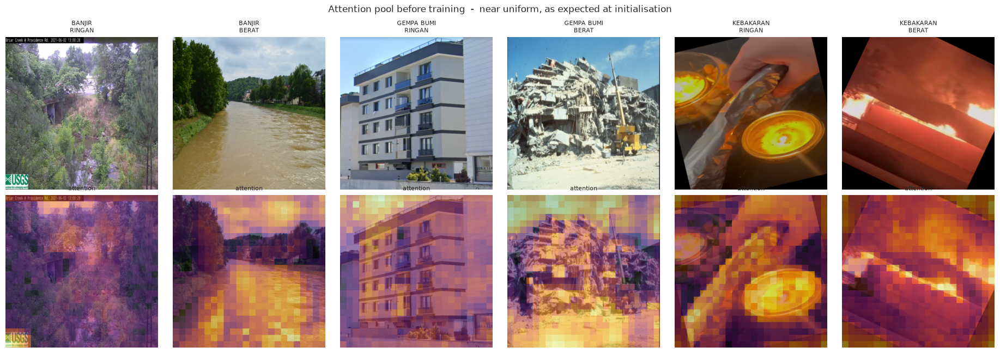

In [36]:
@torch.no_grad()
def attention_overlay(rows, title, fname):
    model.eval()
    grid = CFG.IMAGE_SIZE // backbone.config.patch_size
    fig, axes = plt.subplots(2, len(rows), figsize=(3.1 * len(rows), 6.6))
    for col, row in enumerate(rows):
        img = load_canonical(row.path)
        x = eval_tf(img).unsqueeze(0).to(CFG.DEVICE)
        with torch.autocast('cuda', dtype=CFG.AUTOCAST_DTYPE):
            model(x)
        w = model.encoder.last_weights[0].float().cpu().numpy().reshape(grid, grid)
        shown = denorm(eval_tf(img))
        axes[0, col].imshow(shown)
        axes[0, col].set_title(f"{row.jenis}\n"
                               f"{row.kerusakan.replace('KERUSAKAN ', '')}", fontsize=8)
        axes[1, col].imshow(shown)
        axes[1, col].imshow(np.kron(w, np.ones((backbone.config.patch_size,) * 2)),
                            cmap='inferno', alpha=0.55)
        axes[1, col].set_title('attention', fontsize=8)
    for ax in axes.ravel():
        ax.axis('off')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(CFG.FIG_DIR / fname, dpi=120)
    plt.show()


ATTN_ROWS = [train_df[(train_df.jenis == j) & (train_df.kerusakan == k)]
             .sample(1, random_state=13).iloc[0]
             for j in CFG.JENIS for k in ('KERUSAKAN RINGAN', 'KERUSAKAN BERAT')]
attention_overlay(ATTN_ROWS, 'Attention pool before training  -  '
                  'near uniform, as expected at initialisation',
                  'attn_before_training.png')

---

## Fungsi Kerugian

Target kerusakan diatur melalui `CFG.SEVERITY_SOFT_TARGET`:

| Opsi          | Keterangan                                                                                 |
| ------------- | ------------------------------------------------------------------------------------------ |
| `'sord'`      | Target lunak berdasarkan jarak antartingkat kerusakan untuk mempertimbangkan urutan kelas. |
| `'empirical'` | Target lunak berdasarkan matriks perbedaan anotasi pada Bagian 4.                          |
| `'none'`      | Target *one-hot* sebagai pembanding.                                                       |

Opsi bawaan adalah **`'sord'`**, berdasarkan ablasi dengan ResNet-50 yang menunjukkan peningkatan akurasi kerusakan sebesar **1,4–1,7 poin persentase** dibandingkan *one-hot*.

Bobot fungsi kerugian ditetapkan sebesar **0,25 untuk jenis**, **1,0 untuk kerusakan kategoris**, dan **0,5 untuk kepala ordinal**, sehingga pelatihan lebih berfokus pada prediksi kerusakan.

Jika CutMix diaktifkan dengan aturan maksimum, target kerusakan mengikuti tingkat yang lebih berat dari kedua citra sumber.

In [37]:
def build_soft_targets(mode):
    """3x3 row-stochastic matrix: row y is the training target for label y."""
    if mode == 'none':
        return np.eye(3)
    if mode == 'sord':
        d = np.abs(np.arange(3)[None, :] - np.arange(3)[:, None])
        e = np.exp(-CFG.SORD_TAU * d)
        return e / e.sum(1, keepdims=True)
    if mode == 'empirical':
        q = np.eye(3) * (1 - CFG.EMPIRICAL_STRENGTH) + NOISE_Q * CFG.EMPIRICAL_STRENGTH
        return q / q.sum(1, keepdims=True)
    raise ValueError(mode)


SOFT_K = torch.tensor(build_soft_targets(CFG.SEVERITY_SOFT_TARGET),
                      dtype=torch.float32, device=CFG.DEVICE)
print(f"severity target matrix, mode '{CFG.SEVERITY_SOFT_TARGET}'")
print(pd.DataFrame(SOFT_K.cpu().numpy(),
                   index=[k.replace('KERUSAKAN ', '') for k in CFG.KERUSAKAN],
                   columns=[k.replace('KERUSAKAN ', '') for k in CFG.KERUSAKAN]
                   ).round(4).to_string())
print()
print('all three options, for comparison')
for mode in ('none', 'sord', 'empirical'):
    m = build_soft_targets(mode)
    print(f'  {mode:<10} diagonal {np.diag(m).mean():.3f} | '
          f'one rank {(m[0, 1] + m[2, 1]) / 2:.3f} | '
          f'two ranks {(m[0, 2] + m[2, 0]) / 2:.4f}')
print()
print("'empirical' sits near the measured ~10% noise rate; 'sord' at tau=1.0 is "
      'deliberately softer than that and acts as an ordinal-distance penalty. '
      'The ablation measured the second one.')


def smooth(target, eps):
    return target * (1 - eps) + eps / target.shape[-1]


def soft_ce(logits, target_idx, weight=1.0, soft_matrix=None):
    if soft_matrix is None:
        return weight * Fn.cross_entropy(logits, target_idx,
                                         label_smoothing=CFG.LABEL_SMOOTHING)
    t = smooth(soft_matrix[target_idx], CFG.LABEL_SMOOTHING)
    return weight * -(t * torch.log_softmax(logits, dim=-1)).sum(-1).mean()


def corn_nll(logits_ordinal, y, weight=1.0):
    """Each threshold is trained only on the examples that reached it."""
    total, n = 0.0, 0
    reached = torch.ones_like(y, dtype=torch.bool)
    for t in range(logits_ordinal.shape[1]):
        if reached.any():
            total = total + Fn.binary_cross_entropy_with_logits(
                logits_ordinal[reached, t], (y[reached] > t).float())
            n += 1
        reached = reached & (y > t)
    return weight * total / max(n, 1)


def compute_loss(logits, targets, perm, lam, kind):
    l9, lj, lk, lo = logits
    y9, yj, yk = targets
    ka, kb, kw = severity_mix_targets(yk, perm, lam, kind)

    def area_mixed(fn, ya, yb, w):
        if perm is None:
            return fn(ya)
        return w * fn(ya) + (1 - w) * fn(yb)

    loss_joint = area_mixed(lambda y: soft_ce(l9, y),
                            y9, y9[perm] if perm is not None else y9, lam)
    loss_jenis = area_mixed(lambda y: soft_ce(lj, y),
                            yj, yj[perm] if perm is not None else yj, lam)
    loss_kerusakan = area_mixed(lambda y: soft_ce(lk, y, soft_matrix=SOFT_K),
                                ka, kb, kw)
    loss_ordinal = (torch.zeros((), device=lk.device) if lo is None else
                    area_mixed(lambda y: corn_nll(lo, y), ka, kb, kw))

    total = (CFG.W_JOINT * loss_joint + CFG.W_JENIS * loss_jenis
             + CFG.W_KERUSAKAN * loss_kerusakan + CFG.W_ORDINAL * loss_ordinal)
    return total, loss_joint.detach(), loss_jenis.detach(), loss_kerusakan.detach()


_y = torch.tensor([0, 1, 2], device=CFG.DEVICE)
_perfect = torch.eye(3, device=CFG.DEVICE) * 20.0
print()
print(f'soft CE of a perfect prediction under this target matrix: '
      f'{soft_ce(_perfect, _y, soft_matrix=SOFT_K).item():.4f}  '
      f'(one-hot control {soft_ce(_perfect, _y).item():.4f})')
_adjacent = _perfect[[1, 0, 1]]
_far = _perfect[[2, 2, 0]]
_near_loss = soft_ce(_adjacent, _y, soft_matrix=SOFT_K).item()
_far_loss = soft_ce(_far, _y, soft_matrix=SOFT_K).item()
print(f'one rank wrong {_near_loss:.4f} vs two ranks wrong {_far_loss:.4f}')
if CFG.SEVERITY_SOFT_TARGET == 'none':
    assert abs(_near_loss - _far_loss) < 1e-4, \
        'a one-hot target must be indifferent to rank distance'
    print('verified: one-hot, so every wrong rank costs the same')
else:
    assert _near_loss < _far_loss, 'the target must penalise distance'
    print('verified: the target penalises rank distance')
print('verified: the severity objective costs more for a two-rank error than a one-rank one')

severity target matrix, mode 'sord'
        RINGAN  SEDANG   BERAT
RINGAN  0.6652  0.2447  0.0900
SEDANG  0.2119  0.5761  0.2119
BERAT   0.0900  0.2447  0.6652

all three options, for comparison
  none       diagonal 1.000 | one rank 0.000 | two ranks 0.0000
  sord       diagonal 0.636 | one rank 0.245 | two ranks 0.0900
  empirical  diagonal 0.885 | one rank 0.094 | two ranks 0.0158

'empirical' sits near the measured ~10% noise rate; 'sord' at tau=1.0 is deliberately softer than that and acts as an ordinal-distance penalty. The ablation measured the second one.

soft CE of a perfect prediction under this target matrix: 7.5915  (one-hot control 0.6667)
one rank wrong 15.2245 vs two ranks wrong 17.1840
verified: the target penalises rank distance
verified: the severity objective costs more for a two-rank error than a one-rank one


---

## Penggabungan Prediksi dan Metrik

Prediksi kerusakan menggabungkan tiga sumber: probabilitas dari kepala gabungan yang dijumlahkan atas jenis, kepala kategoris, dan kepala ordinal. Bobot penggabungan berjumlah satu dan disetel pada data validasi di Bagian 8. Prediksi jenis tetap menggunakan gabungan dua sumber.

Penyesuaian skor per kelas digunakan untuk mengurangi kecenderungan prediksi ke kelas tengah. Nilai awalnya nol dan disetel pada Bagian 8, dengan proses penggabungan yang sama untuk pelatihan, validasi, dan pengujian.

In [38]:
SEV_OFFSET = np.zeros(3)


def severity_posterior(p9, pk, po, weights):
    """Blend the three severity estimates. weights = (joint, categorical, ordinal)."""
    wj, wc, wo = weights
    out = wj * p9.reshape(-1, 3, 3).sum(axis=1) + wc * pk
    if po is not None:
        out = out + wo * po
    return out / max(wj + wc + (wo if po is not None else 0.0), 1e-9)


def decode(p9, pj, pk, po, alpha_j, sev_weights, offset=None):
    marg_j = p9.reshape(-1, 3, 3).sum(axis=2)
    pred_j = (alpha_j * marg_j + (1 - alpha_j) * pj).argmax(1)
    post_k = severity_posterior(p9, pk, po, sev_weights)
    logp = np.log(np.clip(post_k, 1e-9, None))
    if offset is not None:
        logp = logp + np.asarray(offset)
    return pred_j, logp.argmax(1)


def competition_micro_f1(true_j, pred_j, true_k, pred_k):
    y_true = np.concatenate([np.asarray(true_j), np.asarray(true_k) + 3])
    y_pred = np.concatenate([np.asarray(pred_j), np.asarray(pred_k) + 3])
    return f1_score(y_true, y_pred, average='micro')


_rng = np.random.default_rng(0)
_tj, _tk = _rng.integers(0, 3, 200), _rng.integers(0, 3, 200)
_pj, _pk = _tj.copy(), _tk.copy()
_pj[:20] = (_pj[:20] + 1) % 3
_pk[:40] = (_pk[:40] + 1) % 3
assert abs(competition_micro_f1(_tj, _pj, _tk, _pk)
           - ((_tj == _pj).mean() + (_tk == _pk).mean()) / 2) < 1e-9
print('verified: micro F1 over the 900 rows equals the mean of the two accuracies')

_p9 = _rng.dirichlet(np.ones(9), 50)
_pk3 = _rng.dirichlet(np.ones(3), 50)
_po3 = _rng.dirichlet(np.ones(3), 50)
assert np.allclose(severity_posterior(_p9, _pk3, _po3, (1, 0, 0)),
                   _p9.reshape(-1, 3, 3).sum(1))
assert np.allclose(severity_posterior(_p9, _pk3, _po3, (0, 1, 0)), _pk3)
assert np.allclose(severity_posterior(_p9, _pk3, _po3, (0, 0, 1)), _po3)
print('verified: the severity blend reduces to each of its three sources at the corners')

verified: micro F1 over the 900 rows equals the mean of the two accuracies
verified: the severity blend reduces to each of its three sources at the corners


---

## Optimizer dan Jadwal Laju Pembelajaran

Blok *encoder* menggunakan laju pembelajaran yang menurun per lapis. Modul *attention pooling* menggunakan laju pembelajaran yang sama dengan kepala klasifikasi karena diinisialisasi secara acak dan memerlukan pembaruan lebih besar daripada *backbone*.


In [39]:
def build_param_groups(model):
    groups = []
    # head and the freshly initialised attention pool share the head LR
    new_decay, new_nodecay = [], []
    for module in (model.head, model.encoder.pool):
        for _, p in module.named_parameters():
            if p.requires_grad:
                (new_nodecay if p.ndim <= 1 else new_decay).append(p)
    groups.append({'params': new_decay, 'lr': CFG.HEAD_LR, 'weight_decay': CFG.WEIGHT_DECAY})
    groups.append({'params': new_nodecay, 'lr': CFG.HEAD_LR, 'weight_decay': 0.0})

    pool_ids = {id(p) for p in model.encoder.pool.parameters()}
    depths = encoder_layer_depths(model.encoder)
    max_depth = max(depths.values()) if depths else 1
    buckets = {}
    for name, p in model.encoder.named_parameters():
        if not p.requires_grad or id(p) in pool_ids:
            continue
        scale = CFG.LLRD ** (max_depth - depths.get(name, max_depth))
        buckets.setdefault((round(scale, 6), p.ndim <= 1), []).append(p)
    for (scale, is_norm), params in sorted(buckets.items()):
        groups.append({'params': params, 'lr': CFG.BACKBONE_LR * scale,
                       'weight_decay': 0.0 if is_norm else CFG.WEIGHT_DECAY})
    return [g for g in groups if g['params']]


def cosine_with_warmup(optimizer, warmup_steps, total_steps):
    def fn(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return CFG.MIN_LR_RATIO + (1 - CFG.MIN_LR_RATIO) * 0.5 * (1 + math.cos(math.pi * progress))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)


param_groups = build_param_groups(model)
_grouped = sum(len(g['params']) for g in param_groups)
_trainable = sum(1 for p in model.parameters() if p.requires_grad)
assert _grouped == _trainable, f'{_grouped} grouped vs {_trainable} trainable'
print(f'parameter groups : {len(param_groups)}')
print(f'learning rates   : {sorted({round(g["lr"], 8) for g in param_groups})}')
print(f'verified: all {_trainable} trainable tensors are in exactly one group, '
      f'the attention pool at the head rate {CFG.HEAD_LR}')

parameter groups : 15
learning rates   : [1.07e-06, 1.42e-06, 1.9e-06, 2.53e-06, 3.37e-06, 4.5e-06, 6e-06, 0.001]
verified: all 126 trainable tensors are in exactly one group, the attention pool at the head rate 0.001


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Training <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

> **Bagian ini hanya berjalan ketika `CFG.RUN_MODE == 'TRAIN'`, dan memakan waktu sekitar 4 jam pada GPU yang tercetak di bagian 2.** Gunakan mode `'INFERENCE'` untuk langsung ke [bagian 9, Inferensi dan Submisi](#9)

In [40]:
def run_train_epoch(model, loader, optimizer, scheduler, epoch):
    model.train()
    running = {'loss': 0.0, 'joint': 0.0, 'jenis': 0.0, 'kerusakan': 0.0}
    seen = 0
    optimizer.zero_grad(set_to_none=True)
    bar = tqdm(loader, desc=f'epoch {epoch:>2} [train]', leave=False)
    for step, (x, y9, yj, yk) in enumerate(bar):
        x = x.to(CFG.DEVICE, non_blocking=True)
        y9 = y9.to(CFG.DEVICE, non_blocking=True)
        yj = yj.to(CFG.DEVICE, non_blocking=True)
        yk = yk.to(CFG.DEVICE, non_blocking=True)
        x, perm, lam, kind = mix_batch(x, CFG.P_MIX, CFG.MIXUP_ALPHA, CFG.CUTMIX_ALPHA)

        with torch.autocast('cuda', dtype=CFG.AUTOCAST_DTYPE):
            logits = model(x)
        logits = tuple(None if t is None else t.float() for t in logits)
        loss, l9, lj, lk = compute_loss(logits, (y9, yj, yk), perm, lam, kind)
        (loss / CFG.ACCUM_STEPS).backward()

        if (step + 1) % CFG.ACCUM_STEPS == 0:
            torch.nn.utils.clip_grad_norm_(
                [p for g in optimizer.param_groups for p in g['params']], CFG.GRAD_CLIP)
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        bs = x.size(0)
        seen += bs
        running['loss'] += loss.item() * bs
        running['joint'] += l9.item() * bs
        running['jenis'] += lj.item() * bs
        running['kerusakan'] += lk.item() * bs
        bar.set_postfix(loss=f"{running['loss'] / seen:.4f}",
                        lr=f"{scheduler.get_last_lr()[0]:.2e}")
    return {k: v / max(seen, 1) for k, v in running.items()}


@torch.no_grad()
def run_eval_epoch(model, loader, epoch, desc='valid'):
    model.eval()
    p9, pj, pk, po, t9, tj, tk = [], [], [], [], [], [], []
    total_loss, seen = 0.0, 0
    for x, y9, yj, yk in tqdm(loader, desc=f'epoch {epoch:>2} [{desc}]', leave=False):
        x = x.to(CFG.DEVICE, non_blocking=True)
        with torch.autocast('cuda', dtype=CFG.AUTOCAST_DTYPE):
            l9, lj, lk, lo = model(x)
        l9, lj, lk = l9.float(), lj.float(), lk.float()
        total_loss += Fn.cross_entropy(l9, y9.to(CFG.DEVICE)).item() * x.size(0)
        seen += x.size(0)
        p9.append(l9.softmax(-1).cpu().numpy())
        pj.append(lj.softmax(-1).cpu().numpy())
        pk.append(lk.softmax(-1).cpu().numpy())
        if lo is not None:
            po.append(corn_to_probs(lo.float()).cpu().numpy())
        t9.append(y9.numpy()); tj.append(yj.numpy()); tk.append(yk.numpy())
    return {
        'loss': total_loss / max(seen, 1),
        'p9': np.concatenate(p9), 'pj': np.concatenate(pj), 'pk': np.concatenate(pk),
        'po': np.concatenate(po) if po else None,
        't9': np.concatenate(t9), 'tj': np.concatenate(tj), 'tk': np.concatenate(tk),
    }


DEFAULT_SEV_WEIGHTS = (0.5, 0.5, 0.5) if CFG.USE_ORDINAL_HEAD else (0.5, 0.5, 0.0)


def summarise(out, alpha_j=None, sev_weights=None, offset=None):
    pred_j, pred_k = decode(out['p9'], out['pj'], out['pk'], out['po'],
                            CFG.DECODE_ALPHA if alpha_j is None else alpha_j,
                            DEFAULT_SEV_WEIGHTS if sev_weights is None else sev_weights,
                            offset)
    return {
        'acc_jenis': accuracy_score(out['tj'], pred_j),
        'acc_kerusakan': accuracy_score(out['tk'], pred_k),
        'acc_joint9': accuracy_score(out['t9'], out['p9'].argmax(1)),
        'micro_f1': competition_micro_f1(out['tj'], pred_j, out['tk'], pred_k),
        'pred_k_dist': np.bincount(pred_k, minlength=3) / len(pred_k),
    }

---

## Model Setup

In [41]:
def fit_fold(fold):
    seed_everything(CFG.SEED + fold)
    tr, va, train_loader, val_loader = make_loaders(fold)
    print(f'fold {fold}: train {len(tr):,}  valid {len(va):,}')
    print(f'true severity share on this fold: '
          f'{np.bincount(va.kerusakan.map(CFG.KERUSAKAN_TO_IDX), minlength=3) / len(va)}')

    steps_per_epoch = max(1, len(train_loader) // CFG.ACCUM_STEPS)
    total_steps = steps_per_epoch * CFG.EPOCHS
    optimizer = torch.optim.AdamW(build_param_groups(model), betas=(0.9, 0.999), eps=1e-6)
    scheduler = cosine_with_warmup(optimizer, int(total_steps * CFG.WARMUP_RATIO), total_steps)

    history, best_f1 = [], -1.0
    best_path = CFG.MODEL_PATH
    for epoch in range(1, CFG.EPOCHS + 1):
        t0 = time.time()
        train_stats = run_train_epoch(model, train_loader, optimizer, scheduler, epoch)
        val_out = run_eval_epoch(model, val_loader, epoch)
        m = summarise(val_out)
        row = {'epoch': epoch, 'train_loss': train_stats['loss'],
               'val_loss': val_out['loss'], 'acc_jenis': m['acc_jenis'],
               'acc_kerusakan': m['acc_kerusakan'], 'acc_joint9': m['acc_joint9'],
               'micro_f1': m['micro_f1'], 'share_sedang': float(m['pred_k_dist'][1]),
               'lr': scheduler.get_last_lr()[0], 'seconds': time.time() - t0}
        history.append(row)
        flag = ''
        if m['micro_f1'] > best_f1:
            best_f1 = m['micro_f1']
            torch.save({
                'head': model.head.state_dict(),
                'encoder_trainable': {k: v.detach().cpu() for k, v in
                                      model.encoder.state_dict().items()
                                      if k in TRAINABLE_ENCODER_KEYS},
                'fold': fold, 'epoch': epoch, 'micro_f1': best_f1,
            }, best_path)
            flag = '  <- best, saved'
        print(f"epoch {epoch:>2}/{CFG.EPOCHS} | train {row['train_loss']:.4f} | "
              f"val {row['val_loss']:.4f} | jenis {row['acc_jenis']:.4f} | "
              f"kerusakan {row['acc_kerusakan']:.4f} | microF1 {row['micro_f1']:.4f} | "
              f"SEDANG share {row['share_sedang']:.3f} | {row['seconds']:.0f}s{flag}")

    hist = pd.DataFrame(history)
    hist.to_csv(CFG.OUTPUT_DIR / f'history_fold{fold}.csv', index=False)
    return hist, val_out, va, best_path


FOLDS = list(range(CFG.N_FOLDS)) if CFG.RUN_ALL_FOLDS else [CFG.FOLD]

history, val_out, val_df, val_loader = None, None, None, None

if CFG.RUN_MODE == 'TRAIN':
    t_start = time.time()
    history, val_out, val_df, ckpt_path = fit_fold(FOLDS[0])
    print(f'\ntotal waktu pelatihan: {(time.time() - t_start) / 60:.1f} menit')
else:
    ckpt_path = CFG.MODEL_PATH
    print('RUN_MODE = INFERENCE, pelatihan dilewati.')
    print('bobot akan dimuat di bagian 9 dari path yang ditetapkan sel Path Model.')

fold 0: train 13,985  valid 3,497
true severity share on this fold: [0.29511009 0.38375751 0.3211324 ]


epoch  1 [train]:   0%|          | 0/1748 [00:00<?, ?it/s]

epoch  1 [valid]:   0%|          | 0/219 [00:00<?, ?it/s]

epoch  1/8 | train 2.9001 | val 1.4650 | jenis 0.9934 | kerusakan 0.7338 | microF1 0.8636 | SEDANG share 0.370 | 1271s  <- best, saved


epoch  2 [train]:   0%|          | 0/1748 [00:00<?, ?it/s]

...

epoch  7 [valid]:   0%|          | 0/219 [00:00<?, ?it/s]

epoch  7/8 | train 1.8486 | val 0.7755 | jenis 0.9957 | kerusakan 0.7669 | microF1 0.8813 | SEDANG share 0.443 | 1263s  <- best, saved


epoch  8 [train]:   0%|          | 0/1748 [00:00<?, ?it/s]

epoch  8 [valid]:   0%|          | 0/219 [00:00<?, ?it/s]

epoch  8/8 | train 1.8003 | val 0.7596 | jenis 0.9960 | kerusakan 0.7627 | microF1 0.8793 | SEDANG share 0.429 | 1263s

total waktu pelatihan: 168.9 menit


---

## Learning Curve

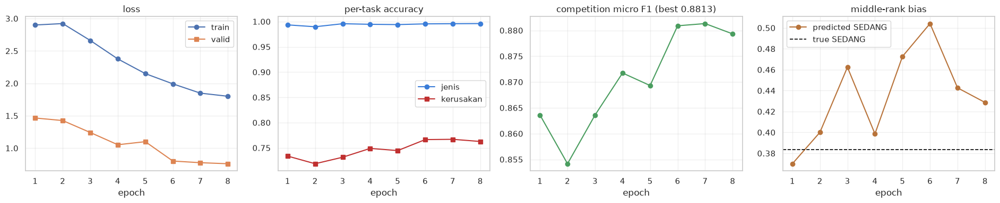

 epoch  train_loss  val_loss  acc_jenis  acc_kerusakan  acc_joint9  micro_f1  share_sedang     lr   seconds
     1      2.9001    1.4650     0.9934         0.7338      0.6995    0.8636        0.3700 0.0010 1270.9110
     2      2.9218    1.4257     0.9897         0.7186      0.7037    0.8542        0.4001 0.0009 1268.7418
     3      2.6614    1.2415     0.9957         0.7315      0.6966    0.8636        0.4624 0.0007 1265.4773
     4      2.3766    1.0526     0.9946         0.7489      0.7486    0.8717        0.3986 0.0006 1263.9959
     5      2.1497    1.0999     0.9940         0.7446      0.7326    0.8693        0.4727 0.0004 1264.3287
     6      1.9921    0.8012     0.9954         0.7664      0.7512    0.8809        0.5041 0.0002 1265.2018
     7      1.8486    0.7755     0.9957         0.7669      0.7778    0.8813        0.4427 0.0001 1262.9579
     8      1.8003    0.7596     0.9960         0.7627      0.7687    0.8793        0.4287 0.0000 1263.3735


In [42]:
if CFG.RUN_MODE == 'TRAIN':
    true_sedang = float((val_df.kerusakan == 'KERUSAKAN SEDANG').mean())
    fig, axes = plt.subplots(1, 4, figsize=(19, 4))
    axes[0].plot(history.epoch, history.train_loss, marker='o', label='train')
    axes[0].plot(history.epoch, history.val_loss, marker='s', label='valid')
    axes[0].set_title('loss'); axes[0].legend()
    axes[1].plot(history.epoch, history.acc_jenis, marker='o', color='#3b7dd8', label='jenis')
    axes[1].plot(history.epoch, history.acc_kerusakan, marker='s', color='#c03030',
                 label='kerusakan')
    axes[1].set_title('per-task accuracy'); axes[1].legend()
    axes[2].plot(history.epoch, history.micro_f1, marker='o', color='#4a9d5f')
    axes[2].set_title(f'competition micro F1 (best {history.micro_f1.max():.4f})')
    axes[3].plot(history.epoch, history.share_sedang, marker='o', color='#b8733a',
                 label='predicted SEDANG')
    axes[3].axhline(true_sedang, ls='--', lw=1.2, color='black', label='true SEDANG')
    axes[3].set_title('middle-rank bias'); axes[3].legend()
    for ax in axes:
        ax.set_xlabel('epoch'); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(CFG.FIG_DIR / 'training_curves.png', dpi=130)
    plt.show()
    print(history.round(4).to_string(index=False))
else:
    # mode INFERENCE: kurva pembelajaran dilewati karena tidak ada pelatihan yang dijalankan.
    pass

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Evaluation <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Memulihkan Checkpoint Terbaik

Hanya kepala, *attention pool* dan tensor *encoder* yang tidak dibekukan yang disimpan; bobot beku kembali dari sumber prapelatihannya.

In [43]:
if CFG.RUN_MODE == 'TRAIN':
    ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    model.head.load_state_dict(ckpt['head'])
    missing = model.encoder.load_state_dict(ckpt['encoder_trainable'], strict=False)
    model.to(CFG.DEVICE).eval()
    print(f"dipulihkan dari lipatan {ckpt['fold']} epos {ckpt['epoch']}, "
          f"micro F1 validasi {ckpt['micro_f1']:.4f}")
    print(f'kunci tak terduga saat memuat encoder: {len(missing.unexpected_keys)}')
    assert not missing.unexpected_keys, missing.unexpected_keys[:5]

    if val_out is None:
        _, _, _, val_loader = make_loaders(CFG.FOLD)
        val_out = run_eval_epoch(model, val_loader, 0, desc='valid')
        del val_loader
        gc.collect()
else:
    # mode INFERENCE: pemulihan checkpoint dilewati, bobot dimuat di bagian 9.
    pass

dipulihkan dari lipatan 0 epos 7, micro F1 validasi 0.8813
kunci tak terduga saat memuat encoder: 0


---

## Ke Mana Perhatian Tertuju

Enam citra yang sama dengan bagian 6, kini dengan *pool* yang sudah terlatih. Inilah pemeriksaan atas apakah pembingkaian *multiple-instance* membeli sesuatu yang nyata: pada adegan berat massa perhatiannya seharusnya memusat pada kerusakan, dan pada adegan ringan ia seharusnya tetap menyebar.

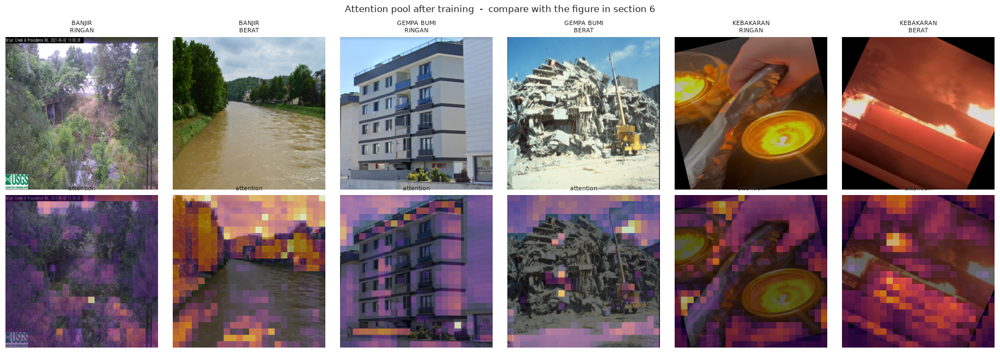

normalised attention entropy by true severity (1.0 = uniform over patches, lower = concentrated)
KERUSAKAN RINGAN    0.9498
KERUSAKAN SEDANG    0.9190
KERUSAKAN BERAT     0.9361


In [44]:
if CFG.RUN_MODE == 'TRAIN':
    attention_overlay(ATTN_ROWS,
                      'Attention pool after training  -  compare with the figure in section 6',
                      'attn_after_training.png')

    @torch.no_grad()
    def attention_entropy(rows):
        model.eval()
        ent = []
        for row in rows.itertuples():
            x = eval_tf(load_canonical(row.path)).unsqueeze(0).to(CFG.DEVICE)
            with torch.autocast('cuda', dtype=CFG.AUTOCAST_DTYPE):
                model(x)
            w = model.encoder.last_weights[0].float().cpu().numpy()
            ent.append(float(-(w * np.log(w + 1e-12)).sum() / np.log(len(w))))
        return np.array(ent)


    # pd.concat over the groups rather than groupby.apply: since pandas 2.2 an
    # apply that returns a frame drops the grouping column, and the entropy is
    # indexed by it two lines further down
    sample_rows = pd.concat(
        [d.sample(min(40, len(d)), random_state=1)
         for _, d in val_df.groupby('kerusakan', sort=False)],
        ignore_index=True)
    ent = attention_entropy(sample_rows)
    ent_by = pd.Series(ent, index=sample_rows.kerusakan.to_numpy()).groupby(level=0).mean()
    print('normalised attention entropy by true severity '
          '(1.0 = uniform over patches, lower = concentrated)')
    print(ent_by.reindex(CFG.KERUSAKAN).round(4).to_string())
else:
    # mode INFERENCE: analisis attention dilewati.
    pass

---

## Severty Blend

Bobot prediksi jenis disetel melalui pencarian satu dimensi pada dua sumber prediksi. Untuk kerusakan, pencarian dilakukan pada kombinasi bobot tiga sumber dengan total bobot satu. Sumber yang tidak meningkatkan skor dapat diberi bobot nol.

In [45]:
if CFG.RUN_MODE == 'TRAIN':
    alphas = np.linspace(0.0, 1.0, 21)
    marg_j = val_out['p9'].reshape(-1, 3, 3).sum(axis=2)
    scan_j = [accuracy_score(val_out['tj'], (a * marg_j + (1 - a) * val_out['pj']).argmax(1))
              for a in alphas]
    BEST_ALPHA_J = float(alphas[int(np.argmax(scan_j))])
    print(f'jenis : marginal head {scan_j[0]:.4f} | joint head {scan_j[-1]:.4f} | '
          f'best {max(scan_j):.4f} at alpha={BEST_ALPHA_J:.2f}')

    steps = np.arange(0, 11) / 10
    candidates = [(a, b, round(1 - a - b, 3)) for a in steps for b in steps
                  if a + b <= 1.0 + 1e-9]
    if val_out['po'] is None:
        candidates = [(a, round(1 - a, 3), 0.0) for a in steps]

    rows = []
    for wgt in candidates:
        post = severity_posterior(val_out['p9'], val_out['pk'], val_out['po'], wgt)
        rows.append((wgt, accuracy_score(val_out['tk'], post.argmax(1))))
    scan_k = pd.DataFrame(rows, columns=['weights', 'acc']).sort_values('acc', ascending=False)
    BEST_SEV_WEIGHTS = tuple(round(float(w), 3) for w in scan_k.iloc[0].weights)
    print()
    print('severity blend, best five  (joint, categorical, ordinal)')
    print(scan_k.head(5).to_string(index=False))
    print()
    for name, wgt in [('joint head alone', (1, 0, 0)), ('categorical alone', (0, 1, 0)),
                      ('ordinal alone', (0, 0, 1)),
                      ('paduan seragam 50/50', (0.5, 0.5, 0.0))]:
        if wgt == (0, 0, 1) and val_out['po'] is None:
            continue
        post = severity_posterior(val_out['p9'], val_out['pk'], val_out['po'], wgt)
        print(f'  {name:<26} {accuracy_score(val_out["tk"], post.argmax(1)):.4f}')
    print(f'  {"tuned blend":<26} {scan_k.iloc[0].acc:.4f}')
else:
    # mode INFERENCE: penalaan paduan dilewati, bobotnya dibaca dari bundel .pt di bagian 9.
    pass

jenis : marginal head 0.9954 | joint head 0.9920 | best 0.9963 at alpha=0.15

severity blend, best five  (joint, categorical, ordinal)
         weights      acc
 (1.0, 0.0, 0.0) 0.771232
(0.9, 0.1, -0.0) 0.770089
(0.8, 0.2, -0.0) 0.769517
 (0.8, 0.0, 0.2) 0.769231
 (0.9, 0.0, 0.1) 0.768945

  joint head alone           0.7712
  categorical alone          0.7383
  ordinal alone              0.7458
  paduan seragam 50/50       0.7638
  tuned blend                0.7712


---

## Log Probability

Menambahkan penyesuaian per kelas pada log probabilitas untuk mengurangi kecenderungan prediksi ke tingkat kerusakan tengah. Dua parameter disetel, sedangkan parameter kelas ketiga ditetapkan nol.

Data validasi dibagi menjadi dua berdasarkan kelompok adegan. Parameter disetel pada bagian pertama dan dievaluasi pada bagian kedua. Kalibrasi hanya digunakan jika meningkatkan skor pada bagian evaluasi, lalu disetel ulang menggunakan seluruh data validasi untuk prediksi data uji.


In [46]:
if CFG.RUN_MODE == 'TRAIN':
    def fit_offsets(post, y):
        g = np.arange(-CFG.CALIBRATION_RANGE, CFG.CALIBRATION_RANGE + 1e-9,
                      CFG.CALIBRATION_GRID)
        logp = np.log(np.clip(post, 1e-9, None))
        best, best_acc = np.zeros(3), -1.0
        for a in g:
            for b in g:
                off = np.array([a, b, 0.0])
                acc = float(((logp + off).argmax(1) == y).mean())
                if acc > best_acc:
                    best_acc, best = acc, off
        return best, best_acc


    def apply_offsets(post, off):
        return (np.log(np.clip(post, 1e-9, None)) + np.asarray(off)).argmax(1)


    val_post_k = severity_posterior(val_out['p9'], val_out['pk'], val_out['po'],
                                    BEST_SEV_WEIGHTS)

    # split the fold in half by scene group, so no scene spans the two halves
    groups = val_df.group.to_numpy()
    uniq = np.unique(groups)
    rs = np.random.default_rng(CFG.SEED).permutation(len(uniq))
    half_a_groups = set(uniq[rs[: len(uniq) // 2]])
    mask_a = np.array([g in half_a_groups for g in groups])
    mask_b = ~mask_a
    assert not (set(groups[mask_a]) & set(groups[mask_b])), 'halves share a scene group'
    print(f'calibration halves: {mask_a.sum()} fit rows, {mask_b.sum()} held-out rows, '
          f'no shared scene group')

    off_a, acc_in = fit_offsets(val_post_k[mask_a], val_out['tk'][mask_a])
    raw_b = float((val_post_k[mask_b].argmax(1) == val_out['tk'][mask_b]).mean())
    cal_b = float((apply_offsets(val_post_k[mask_b], off_a) == val_out['tk'][mask_b]).mean())
    print()
    print(f'offsets fitted on half A      : {np.round(off_a, 3)}')
    print(f'half A accuracy (in-sample)   : {acc_in:.4f}')
    print(f'half B accuracy, uncalibrated : {raw_b:.4f}')
    print(f'half B accuracy, calibrated   : {cal_b:.4f}')
    print(f'honest out-of-sample gain     : {cal_b - raw_b:+.4f}')

    USE_CALIBRATION = bool(CFG.CALIBRATE_SEVERITY and cal_b > raw_b)
    SEV_OFFSET = fit_offsets(val_post_k, val_out['tk'])[0] if USE_CALIBRATION else np.zeros(3)
    print()
    print(f'calibration will be applied to the test set: {USE_CALIBRATION}')
    print(f'offsets refitted on the full fold: {np.round(SEV_OFFSET, 3)}')
else:
    # mode INFERENCE: kalibrasi dilewati, geserannya dibaca dari bundel .pt di bagian 9.
    pass

calibration halves: 2405 fit rows, 1092 held-out rows, no shared scene group

offsets fitted on half A      : [-0.55  0.05  0.  ]
half A accuracy (in-sample)   : 0.7497
half B accuracy, uncalibrated : 0.8498
half B accuracy, calibrated   : 0.8507
honest out-of-sample gain     : +0.0009

calibration will be applied to the test set: True
offsets refitted on the full fold: [-0.6  0.   0. ]


---

## Confusion Matrix

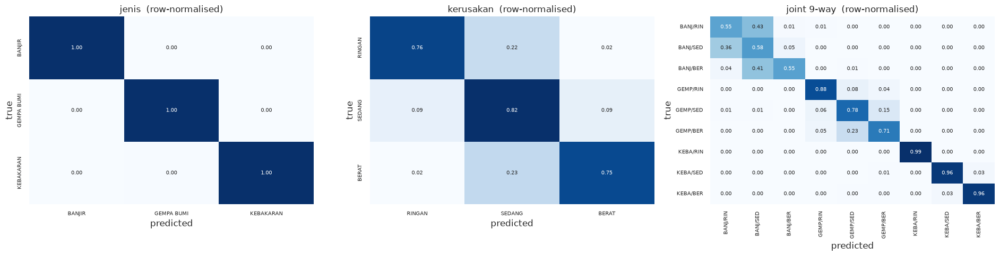

jenis
              precision    recall  f1-score   support

      BANJIR     0.9966    0.9975    0.9971      1191
  GEMPA BUMI     0.9948    0.9957    0.9952      1150
   KEBAKARAN     0.9974    0.9957    0.9965      1156

    accuracy                         0.9963      3497
   macro avg     0.9963    0.9963    0.9963      3497
weighted avg     0.9963    0.9963    0.9963      3497

kerusakan
              precision    recall  f1-score   support

      RINGAN     0.8517    0.7626    0.8047      1032
      SEDANG     0.6950    0.8234    0.7538      1342
       BERAT     0.8545    0.7480    0.7977      1123

    accuracy                         0.7812      3497
   macro avg     0.8004    0.7780    0.7854      3497
weighted avg     0.7925    0.7812    0.7829      3497

severity errors one rank wide : 722
severity errors two ranks wide: 43
edge-class error absorbed by the middle rank: 92%

        true share  predicted share   drift
RINGAN      0.2951           0.2642 -0.0309
SEDANG      

In [47]:
if CFG.RUN_MODE == 'TRAIN':
    pred_j, pred_k = decode(val_out['p9'], val_out['pj'], val_out['pk'], val_out['po'],
                            BEST_ALPHA_J, BEST_SEV_WEIGHTS, SEV_OFFSET)
    best_micro = competition_micro_f1(val_out['tj'], pred_j, val_out['tk'], pred_k)
    short = [k.replace('KERUSAKAN ', '') for k in CFG.KERUSAKAN]

    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    for ax, (true, pred, names, title) in zip(axes, [
        (val_out['tj'], pred_j, CFG.JENIS, 'jenis'),
        (val_out['tk'], pred_k, short, 'kerusakan'),
        (val_out['t9'], val_out['p9'].argmax(1), CFG.CLS9_SHORT, 'joint 9-way'),
    ]):
        sns.heatmap(confusion_matrix(true, pred, normalize='true'), annot=True, fmt='.2f',
                    cmap='Blues', ax=ax, cbar=False, xticklabels=names, yticklabels=names,
                    annot_kws={'size': 7})
        ax.set_title(f'{title}  (row-normalised)')
        ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.tick_params(labelsize=7)
    plt.tight_layout()
    plt.savefig(CFG.FIG_DIR / 'confusion_matrices.png', dpi=130)
    plt.show()

    print('jenis')
    print(classification_report(val_out['tj'], pred_j, target_names=CFG.JENIS, digits=4))
    print('kerusakan')
    print(classification_report(val_out['tk'], pred_k, target_names=short, digits=4))

    cm = confusion_matrix(val_out['tk'], pred_k)
    adjacent = cm[0, 1] + cm[1, 0] + cm[1, 2] + cm[2, 1]
    extreme = cm[0, 2] + cm[2, 0]
    edge_loss = int(cm[0].sum() - cm[0, 0] + cm[2].sum() - cm[2, 2])
    print(f'severity errors one rank wide : {adjacent}')
    print(f'severity errors two ranks wide: {extreme}')
    print(f'edge-class error absorbed by the middle rank: '
          f'{(cm[0, 1] + cm[2, 1]) / max(edge_loss, 1) * 100:.0f}%')
    print()
    ledger = pd.DataFrame({
        'true share': np.bincount(val_out['tk'], minlength=3) / len(val_out['tk']),
        'predicted share': np.bincount(pred_k, minlength=3) / len(pred_k),
    }, index=short)
    ledger['drift'] = ledger['predicted share'] - ledger['true share']
    print(ledger.round(4).to_string())
else:
    # mode INFERENCE: matriks kekeliruan dilewati, tidak ada lipatan validasi yang dievaluasi.
    pass

---

## Missclassification

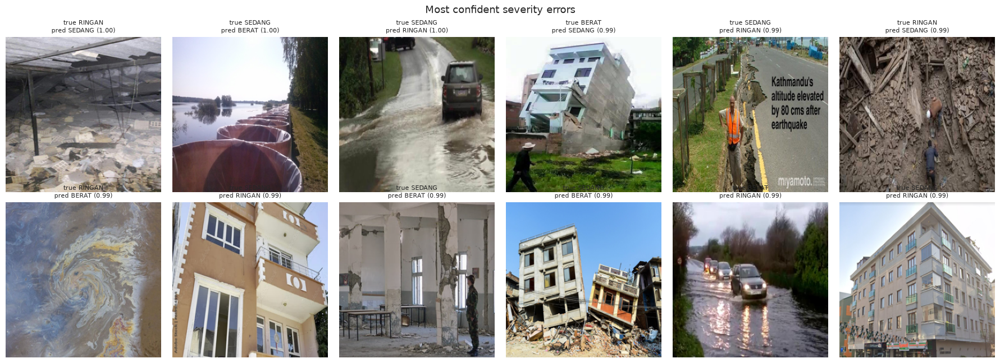

In [48]:
if CFG.RUN_MODE == 'TRAIN':
    conf_k = severity_posterior(val_out['p9'], val_out['pk'], val_out['po'], BEST_SEV_WEIGHTS)
    wrong = np.where(pred_k != val_out['tk'])[0]
    order = wrong[np.argsort(-conf_k[wrong].max(1))][:12]
    if len(order):
        fig, axes = plt.subplots(2, 6, figsize=(18, 6.6))
        for ax, idx in zip(axes.ravel(), order):
            row = val_df.iloc[int(idx)]
            ax.imshow(load_canonical(row.path).resize((256, 256)))
            ax.set_title(f"true {short[val_out['tk'][idx]]}\n"
                         f"pred {short[pred_k[idx]]} ({conf_k[idx].max():.2f})", fontsize=8)
            ax.axis('off')
        for ax in axes.ravel()[len(order):]:
            ax.axis('off')
        fig.suptitle('Most confident severity errors', fontsize=13)
        plt.tight_layout()
        plt.savefig(CFG.FIG_DIR / 'hardest_errors.png', dpi=115)
        plt.show()
else:
    # mode INFERENCE: galeri galat tersulit dilewati.
    pass

#### Insights

> Terdapat beberapa misklasifikasi pada gambar gambar dengan perbedaan severty yang mirip

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Path Model

Sesuaikan dengan path model

In [49]:
MODEL_PATH = CFG.MODEL_PATH

# Sesuaikan baris di atas bila berkas .pt berada di tempat lain, misalnya:
#   Kaggle Dataset : Path('/kaggle/input/bdc-se-2026-dinov3/dinov3_vit7b16_severity.pt')
#   folder lokal   : Path('./dinov3_vit7b16_severity.pt')

MODEL_PATH = Path(MODEL_PATH)
CFG.MODEL_PATH = MODEL_PATH

if CFG.RUN_MODE != 'TRAIN' and not MODEL_PATH.exists():
    raise FileNotFoundError(
        f'RUN_MODE = {CFG.RUN_MODE} tetapi tidak ada berkas bobot di {MODEL_PATH}. '
        'Perbaiki MODEL_PATH pada sel ini, atau setel CFG.RUN_MODE kembali ke TRAIN.')

---

## Load Model

In [50]:
if CFG.RUN_MODE != 'TRAIN':
    BUNDLE = torch.load(MODEL_PATH, map_location='cpu', weights_only=False)

    model.head.load_state_dict(BUNDLE['head'])
    missing = model.encoder.load_state_dict(BUNDLE['encoder_trainable'], strict=False)
    assert not missing.unexpected_keys, missing.unexpected_keys[:5]
    model.to(CFG.DEVICE).eval()

    BEST_ALPHA_J = float(BUNDLE.get('alpha_jenis', CFG.DECODE_ALPHA))
    BEST_SEV_WEIGHTS = tuple(float(w) for w in
                             BUNDLE.get('severity_weights', (0.5, 0.5, 0.0)))
    SEV_OFFSET = np.asarray(BUNDLE.get('severity_offset', [0.0, 0.0, 0.0]), dtype=float)
    USE_CALIBRATION = bool(BUNDLE.get('use_calibration', False))

    bundled_style = BUNDLE.get('label_style')
    if bundled_style and bundled_style != CFG.LABEL_STYLE:
        print(f'catatan: bundel dilatih dengan LABEL_STYLE {bundled_style!r}, '
              f'notebook menulis {CFG.LABEL_STYLE!r}')

---

## Predict Function

In [51]:
@torch.no_grad()
def predict(model, df):
    model.eval()
    loader = DataLoader(
        DisasterDataset(df, eval_tf, has_labels=False),
        batch_size=CFG.EVAL_BATCH_SIZE, shuffle=False,
        num_workers=CFG.NUM_WORKERS, pin_memory=True,
        persistent_workers=False)

    p9 = np.zeros((len(df), 9))
    pj = np.zeros((len(df), 3))
    pk = np.zeros((len(df), 3))
    po = np.zeros((len(df), 3))
    has_ordinal = False
    offset = 0
    for x, _, _, _ in tqdm(loader, leave=False, desc='prediksi'):
        x = x.to(CFG.DEVICE, non_blocking=True)
        with torch.autocast('cuda', dtype=CFG.AUTOCAST_DTYPE):
            l9, lj, lk, lo = model(x)
        bs = x.size(0)
        p9[offset:offset + bs] = l9.float().softmax(-1).cpu().numpy()
        pj[offset:offset + bs] = lj.float().softmax(-1).cpu().numpy()
        pk[offset:offset + bs] = lk.float().softmax(-1).cpu().numpy()
        if lo is not None:
            has_ordinal = True
            po[offset:offset + bs] = corn_to_probs(lo.float()).cpu().numpy()
        offset += bs

    del loader
    gc.collect()
    return {'p9': p9, 'pj': pj, 'pk': pk, 'po': po if has_ordinal else None}


---

## Inference

In [52]:
test_out = predict(model, test_df)
pred_test_j, pred_test_k = decode(test_out['p9'], test_out['pj'], test_out['pk'],
                                  test_out['po'], BEST_ALPHA_J, BEST_SEV_WEIGHTS,
                                  SEV_OFFSET)

np.savez_compressed(CFG.OUTPUT_DIR / f'{CFG.RUN_NAME}_test_probs.npz',
                    p9=test_out['p9'], pj=test_out['pj'], pk=test_out['pk'],
                    po=test_out['po'] if test_out['po'] is not None else np.zeros(1),
                    image_id=test_df.image_id.to_numpy())

prediksi:   0%|          | 0/29 [00:01<?, ?it/s]

---

## Format Label dan Submisi

Prediksi dikonversi menjadi kode bilangan bulat sesuai format kompetisi:

| Target      | 1      | 2          | 3         |
| ----------- | ------ | ---------- | --------- |
| `jenis`     | BANJIR | GEMPA BUMI | KEBAKARAN |
| `kerusakan` | BERAT  | RINGAN     | SEDANG    |

Selama pemodelan, kerusakan menggunakan indeks internal **0–1–2 untuk ringan–sedang–berat**. Konversi ke kode kompetisi hanya dilakukan saat menyimpan submisi.

`CFG.LABEL_STYLE` mengatur format label, sedangkan `CFG.SUBMISSION_SEP` mengatur pemisah kolom. Perubahan keduanya cukup diterapkan dengan menjalankan ulang dua sel berikut, tanpa pelatihan ulang.


In [ ]:
LABEL_STYLES = {
    'folder': {'jenis': ['BANJIR', 'GEMPA BUMI', 'KEBAKARAN'],
               'kerusakan': ['KERUSAKAN RINGAN', 'KERUSAKAN SEDANG', 'KERUSAKAN BERAT']},
    'title': {'jenis': ['Banjir', 'Gempa Bumi', 'Kebakaran'],
              'kerusakan': ['Ringan', 'Sedang', 'Berat']},
    'short': {'jenis': ['BANJIR', 'GEMPA BUMI', 'KEBAKARAN'],
              'kerusakan': ['RINGAN', 'SEDANG', 'BERAT']},
    'numeric': {'jenis': ['1', '2', '3'], 'kerusakan': ['2', '3', '1']},
}
vocab = LABEL_STYLES[CFG.LABEL_STYLE]

assert len(set(vocab['jenis'])) == 3 and len(set(vocab['kerusakan'])) == 3, \
    'kosakata label harus memetakan tiga kelas ke tiga nilai berbeda'
if CFG.LABEL_STYLE == 'numeric':
    assert vocab['kerusakan'] == ['2', '3', '1'], \
        'penomoran panitia: RINGAN 2, SEDANG 3, BERAT 1'

In [55]:
pred_map = {}
for i, image_id in enumerate(test_df.image_id.tolist()):
    pred_map[f'{image_id}_jenis'] = vocab['jenis'][int(pred_test_j[i])]
    pred_map[f'{image_id}_kerusakan'] = vocab['kerusakan'][int(pred_test_k[i])]

ids = (template.ID.astype(str).tolist() if template is not None else
       [f'{i}_{s}' for i in test_df.image_id for s in ('jenis', 'kerusakan')])
unmatched = [i for i in ids if i not in pred_map]
assert not unmatched, f'{len(unmatched)} baris templat tanpa prediksi, mis. {unmatched[:5]}'

submission = pd.DataFrame({'ID': ids, 'Target': [pred_map[i] for i in ids]})
submission_path = CFG.ROOT_DIR / f'submission_{CFG.RUN_NAME}.csv'
submission.to_csv(submission_path, sep=CFG.SUBMISSION_SEP, index=False)

check = pd.read_csv(submission_path, sep=CFG.SUBMISSION_SEP, dtype=str)
assert list(check.columns) == ['ID', 'Target'], check.columns.tolist()
assert len(check) == len(ids) and check.Target.notna().all()
assert check.ID.str.endswith(('_jenis', '_kerusakan')).all()
assert set(check[check.ID.str.endswith('_jenis')].Target) <= set(vocab['jenis'])
assert set(check[check.ID.str.endswith('_kerusakan')].Target) <= set(vocab['kerusakan'])
if template is not None:
    assert check.ID.tolist() == template.ID.astype(str).tolist(), 'urutan baris berbeda'

print(f'submisi ditulis: {submission_path}  ({len(check)} baris)')

submisi ditulis: submission_dinov3_vit7b16_severity.csv  (900 baris)


---

## Menyimpan Bundel Model

In [56]:
if CFG.RUN_MODE == 'TRAIN':
    bundle_path = CFG.MODEL_PATH
    torch.save({
        'model_id': CFG.MODEL_ID, 'image_size': CFG.IMAGE_SIZE,
        'jenis_dim': JENIS_DIM, 'sev_dim': SEV_DIM,
        'img_mean': IMG_MEAN, 'img_std': IMG_STD,
        'head': model.head.state_dict(),
        'encoder_trainable': {k: v.detach().cpu() for k, v in model.encoder.state_dict().items()
                              if k in TRAINABLE_ENCODER_KEYS},
        'alpha_jenis': BEST_ALPHA_J, 'severity_weights': BEST_SEV_WEIGHTS,
        'severity_offset': SEV_OFFSET.tolist(), 'use_calibration': USE_CALIBRATION,
        'noise_q': NOISE_Q.tolist(), 'soft_target_mode': CFG.SEVERITY_SOFT_TARGET,
        'val_micro_f1': float(best_micro),
        'label_style': CFG.LABEL_STYLE,
    }, bundle_path)
    print(f'bundel ringkas : {bundle_path}  ({bundle_path.stat().st_size / 1e6:.1f} MB)')

    if CFG.SAVE_FULL_WEIGHTS:
        full_path = CFG.ROOT_DIR / f'{CFG.RUN_NAME}_full.pt'
        torch.save(model.state_dict(), full_path)
        print(f'state dict penuh: {full_path}  ({full_path.stat().st_size / 1e9:.2f} GB)')
    else:
        print('state dict penuh dilewati (CFG.SAVE_FULL_WEIGHTS = False)')
else:
    # mode INFERENCE: bundel tidak ditulis ulang, berkas yang dimuat dibiarkan apa adanya.
    pass

bundel ringkas : dinov3_vit7b16_severity.pt  (2032.4 MB)
state dict penuh dilewati (CFG.SAVE_FULL_WEIGHTS = False)


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Kesimpulan <a name="10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

In [ ]:
if CFG.RUN_MODE == 'TRAIN':
    final_j = accuracy_score(val_out['tj'], pred_j)
    final_k = accuracy_score(val_out['tk'], pred_k)

    hasil = pd.Series({'acc jenis': final_j, 'acc kerusakan': final_k,
                       'micro F1': best_micro}).round(4)
    print(hasil.to_string())
    print()
    print(f'langit mayoritas kelompok adegan : {SCENE_CEILING:.4f}')
    print(f'sisa jarak akurasi kerusakan     : {SCENE_CEILING - final_k:.4f}')
    print()
    summary = pd.Series({
        'backbone': CFG.MODEL_ID,
        'ukuran masukan': CFG.IMAGE_SIZE,
        'aliran kerusakan': ', '.join(CFG.SEVERITY_STREAMS),
        'mode target lunak': CFG.SEVERITY_SOFT_TARGET,
        'pengondisian jenis': CFG.USE_TYPE_FILM,
        'kepala ordinal': CFG.USE_ORDINAL_HEAD,
        'paduan kerusakan (joint, kat, ord)': str(BEST_SEV_WEIGHTS),
        'kalibrasi diterapkan': USE_CALIBRATION,
        'geseran kerusakan': str(np.round(SEV_OFFSET, 3)),
        'tampilan evaluasi': 'bingkai penuh',
        'parameter terlatih (juta)': round(n_train / 1e6, 1),
        'micro F1 validasi': round(float(best_micro), 4),
        'baris submisi': len(check),
    })
    print(summary.to_string())
    summary.to_csv(CFG.OUTPUT_DIR / 'summary.csv')
else:
    pass

acc jenis        0.9963
acc kerusakan    0.7812
micro F1         0.8888

langit mayoritas kelompok adegan : 0.9267
sisa jarak akurasi kerusakan     : 0.1455

backbone                              facebook/dinov3-vit7b16-pretrain-lvd1689m
ukuran masukan                                                              384
aliran kerusakan                                          cls, mean, attn, topk
mode target lunak                                                          sord
pengondisian jenis                                                         True
kepala ordinal                                                             True
paduan kerusakan (joint, kat, ord)                              (1.0, 0.0, 0.0)
kalibrasi diterapkan                                                       True
geseran kerusakan                                              [-0.6  0.   0. ]
tampilan evaluasi                                                 bingkai penuh
parameter terlatih (juta)                 

#### Insights

| Aspek                 | Insight utama                                                                                                                                                                         |
| --------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Fokus pemodelan       | Prediksi kerusakan lebih sulit daripada jenis bencana, sehingga mendapat prioritas dalam rancangan arsitektur dan pembobotan fungsi kerugian.                                         |
| Pembagian data        | Pengelompokan adegan, termasuk duplikat hasil rotasi dan pencerminan, membantu mencegah kebocoran antara data pelatihan dan validasi.                                                 |
| Perbedaan anotasi     | Pola ketidaksepakatan label dihitung dengan bobot yang sama per adegan agar tidak didominasi kelompok citra terbesar.                                                                 |
| Tampilan citra        | Evaluasi menggunakan bingkai penuh untuk mempertahankan bukti kerusakan di tepi citra. Transformasi yang sama diterapkan pada 35% sampel pelatihan.                                   |
| Augmentasi            | *RandomErasing* dibatasi untuk mengurangi risiko hilangnya bukti kerusakan. Derau Gaussian ditambahkan untuk mengurangi ketergantungan pada pola derau yang berkorelasi dengan label. |
| Strategi pencampuran  | MixUp tanpa CutMix meningkatkan skor sebesar **0,002–0,006** dalam ablasi pengembangan.                                                                                               |
| Agregasi fitur        | *Attention pooling* dan *top-k pooling* menonjolkan bukti lokal, sementara CLS dan *mean pooling* mempertahankan informasi global.                                                    |
| Pengondisian jenis    | FiLM menyesuaikan fitur kerusakan dengan prediksi jenis bencana untuk mengakomodasi perbedaan indikator kerusakan.                                                                    |
| Target ordinal        | SORD mempertimbangkan urutan tingkat kerusakan dan meningkatkan akurasi sebesar **1,4–1,7 poin persentase** dibandingkan *one-hot* pada ablasi ResNet-50.                             |
| Penggabungan prediksi | Tiga estimasi kerusakan digabungkan menggunakan bobot yang disetel pada data validasi. Kepala CORN memberi peningkatan kecil saat diuji sendiri (**+0,003**).                         |

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Terima Kasih! <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">